In [1]:
from pathlib import Path
from google.colab import drive

# Mount Google Drive. Colab will prompt you to authorize access.
drive.mount("/content/drive")

# Project paths
PROJECT_ROOT = Path("/content/drive/MyDrive/Marswalk")
DOCUMENTATION_DIR = PROJECT_ROOT / "Documentation"
NOTEBOOKS_DIR = PROJECT_ROOT / "Notebooks"
OUTPUTS_DIR = PROJECT_ROOT / "Outputs"
RAW_DATA_DIR = PROJECT_ROOT / "Raw data"
PROCESSED_DATA_DIR = PROJECT_ROOT / "Processed data"

# Check that the project folder and expected subfolders exist.
expected_dirs = {
    "Documentation": DOCUMENTATION_DIR,
    "Notebooks": NOTEBOOKS_DIR,
    "Outputs": OUTPUTS_DIR,
    "Raw data": RAW_DATA_DIR,
    "Processed data": PROCESSED_DATA_DIR,
}

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Could not find {PROJECT_ROOT}. "
        "Check that the folder is named 'Marswalk' under My Drive."
    )

missing = [name for name, path in expected_dirs.items() if not path.is_dir()]

if missing:
    raise FileNotFoundError(
        "These expected project folders were not found: "
        + ", ".join(missing)
    )

print(f"Project folder: {PROJECT_ROOT}")
print("Expected folders found:")
for name, path in expected_dirs.items():
    print(f"  ✓ {name}: {path}")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Marswalk
Expected folders found:
  ✓ Documentation: /content/drive/MyDrive/Marswalk/Documentation
  ✓ Notebooks: /content/drive/MyDrive/Marswalk/Notebooks
  ✓ Outputs: /content/drive/MyDrive/Marswalk/Outputs
  ✓ Raw data: /content/drive/MyDrive/Marswalk/Raw data
  ✓ Processed data: /content/drive/MyDrive/Marswalk/Processed data


In [2]:
import csv
import json
from datetime import datetime, timezone

# Source notes: these describe intended use, not proof that data has been downloaded.
source_registry = [
    {
        "source": "JPL Mars Trek",
        "intended_use": "Mars map and mission-data discovery; record the specific products used.",
        "caveat": "The portal is a source/discovery tool; cite each actual dataset or map product in the project."
    },
    {
        "source": "USGS-NASA Planetary Geologic Mapping Program",
        "intended_use": "Geologic context for the selected Mars location.",
        "caveat": "Record the map title, scale, publication, and source when a specific map is selected."
    },
    {
        "source": "Curiosity proposed-route animation",
        "intended_use": "Visual reference for route-map presentation.",
        "caveat": "Curiosity/Mount Sharp example; do not present it as route data for Jezero."
    },
    {
        "source": "NASA Worldview",
        "intended_use": "Possible interface inspiration.",
        "caveat": "Do not use as a Mars satellite-data layer unless a specific Mars product is verified."
    },
    {
        "source": "Mars Perseverance Raw Images Gallery",
        "intended_use": "Surface photos and visual context near the selected exploration area.",
        "caveat": "Keep available captions, sol/camera information, and image links with each selected image."
    }
]

DOCUMENTATION_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

registry_path = DOCUMENTATION_DIR / "source_registry.json"
with registry_path.open("w", encoding="utf-8") as f:
    json.dump(source_registry, f, indent=2, ensure_ascii=False)

# Inventory files in the two data folders.
inventory = []
for data_dir in (RAW_DATA_DIR, PROCESSED_DATA_DIR):
    for path in sorted(data_dir.rglob("*")):
        if path.is_file():
            stat = path.stat()
            inventory.append({
                "folder": data_dir.name,
                "relative_path": str(path.relative_to(PROJECT_ROOT)),
                "size_bytes": stat.st_size,
                "modified_utc": datetime.fromtimestamp(
                    stat.st_mtime, tz=timezone.utc
                ).isoformat(timespec="seconds")
            })

inventory_path = OUTPUTS_DIR / "input_inventory.csv"
with inventory_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["folder", "relative_path", "size_bytes", "modified_utc"]
    )
    writer.writeheader()
    writer.writerows(inventory)

print(f"Saved source notes: {registry_path}")
print(f"Saved file inventory: {inventory_path}")
print(f"Files found: {len(inventory)}")

if inventory:
    for item in inventory:
        print(f"- [{item['folder']}] {item['relative_path']} ({item['size_bytes']:,} bytes)")
else:
    print("No files found yet in Raw data or Processed data.")

Saved source notes: /content/drive/MyDrive/Marswalk/Documentation/source_registry.json
Saved file inventory: /content/drive/MyDrive/Marswalk/Outputs/input_inventory.csv
Files found: 361
- [Raw data] Raw data/DTEEC_023524_1985_023379_1985_U01.IMG (700,271,460 bytes)
- [Raw data] Raw data/M20_JezeroCrater_CTXDEM_20m.tif (90,345,300 bytes)
- [Raw data] Raw data/PIA25917_hollowed_rock.jpg (144,105 bytes)
- [Raw data] Raw data/USGS_SIM3464/__MACOSX/sim3464_JezeroNili_FINAL/._.DS_Store (120 bytes)
- [Raw data] Raw data/USGS_SIM3464/__MACOSX/sim3464_JezeroNili_FINAL/Metadata/._SIM3464_metadata.xml (2,002 bytes)
- [Raw data] Raw data/USGS_SIM3464/sim3464_JezeroNili_FINAL/.DS_Store (6,148 bytes)
- [Raw data] Raw data/USGS_SIM3464/sim3464_JezeroNili_FINAL/CoordinateSystems/MTM_clon77_5E.prj (408 bytes)
- [Raw data] Raw data/USGS_SIM3464/sim3464_JezeroNili_FINAL/CoordinateSystems/Mars2000_Sphere.prj (193 bytes)
- [Raw data] Raw data/USGS_SIM3464/sim3464_JezeroNili_FINAL/FeatureLayerSymbology/GeoC

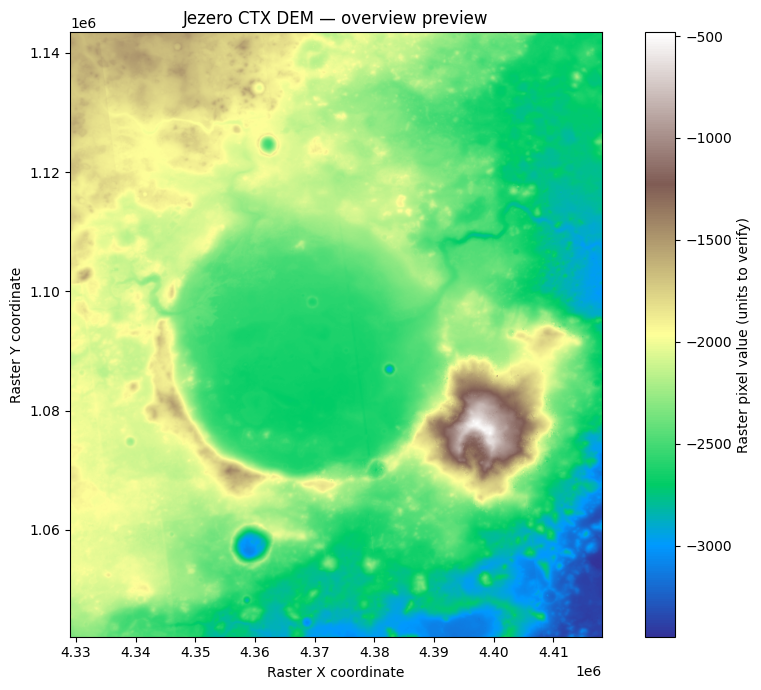

Saved metadata: /content/drive/MyDrive/Marswalk/Outputs/dem_metadata.json
Saved preview:  /content/drive/MyDrive/Marswalk/Outputs/dem_preview.png

Raster summary:
width_pixels: 4456
height_pixels: 5067
crs: PROJCS["Jezero_Crater_Projection",GEOGCS["GCS_Mars_2000_Sphere",DATUM["Mars_2000_(Sphere)",SPHEROID["Mars_2000_Sphere",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",18.4663],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
bounds_in_raster_crs: {'left': 4328999.999999998, 'bottom': 1042080.0000000028, 'right': 4418119.999999998, 'top': 1143420.0000000028}
pixel_size_in_raster_units: [20.0, 20.0]
nodata: -3.4028234663852886e+38
scale: 1.0
offset: 0.0
preview_min: -3446.779052734375
preview_max: -481.65130615234375

Band tags: (none)


In [3]:
from pathlib import Path
import json
import subprocess
import sys

try:
    import rasterio
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "rasterio"])
    import rasterio

import numpy as np
import matplotlib.pyplot as plt
from rasterio.enums import Resampling

dem_path = RAW_DATA_DIR / "M20_JezeroCrater_CTXDEM_20m.tif"
if not dem_path.is_file():
    raise FileNotFoundError(f"DEM not found: {dem_path}")

metadata_path = OUTPUTS_DIR / "dem_metadata.json"
preview_path = OUTPUTS_DIR / "dem_preview.png"

with rasterio.open(dem_path) as src:
    band = 1

    # Read a smaller overview for inspection and plotting.
    preview_height = min(src.height, 1200)
    preview_width = min(src.width, 1200)
    preview = src.read(
        band,
        out_shape=(preview_height, preview_width),
        resampling=Resampling.average,
        masked=True,
    )

    valid = preview.compressed()
    if valid.size == 0:
        raise ValueError("The preview contains no valid pixels; check the raster's nodata metadata.")

    band_tags = src.tags(band)
    metadata = {
        "file": str(dem_path),
        "driver": src.driver,
        "width_pixels": src.width,
        "height_pixels": src.height,
        "band_count": src.count,
        "data_type": src.dtypes[band - 1],
        "crs": str(src.crs) if src.crs else None,
        "bounds_in_raster_crs": {
            "left": src.bounds.left,
            "bottom": src.bounds.bottom,
            "right": src.bounds.right,
            "top": src.bounds.top,
        },
        "pixel_size_in_raster_units": list(src.res),
        "nodata": src.nodata,
        "scale": src.scales[band - 1],
        "offset": src.offsets[band - 1],
        "dataset_tags": src.tags(),
        "band_tags": band_tags,
        "preview_valid_pixel_count": int(valid.size),
        "preview_min": float(valid.min()),
        "preview_max": float(valid.max()),
        "preview_mean": float(valid.mean()),
    }

    # Save the preview with axes in the raster's native coordinate system.
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(
        preview,
        extent=(src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top),
        origin="upper",
        cmap="terrain",
    )
    ax.set_title("Jezero CTX DEM — overview preview")
    ax.set_xlabel("Raster X coordinate")
    ax.set_ylabel("Raster Y coordinate")
    fig.colorbar(image, ax=ax, label="Raster pixel value (units to verify)")
    fig.tight_layout()
    fig.savefig(preview_path, dpi=160)
    plt.show()

with metadata_path.open("w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"Saved metadata: {metadata_path}")
print(f"Saved preview:  {preview_path}")
print("\nRaster summary:")
for key in (
    "width_pixels",
    "height_pixels",
    "crs",
    "bounds_in_raster_crs",
    "pixel_size_in_raster_units",
    "nodata",
    "scale",
    "offset",
    "preview_min",
    "preview_max",
):
    print(f"{key}: {metadata[key]}")
print("\nBand tags:", band_tags or "(none)")

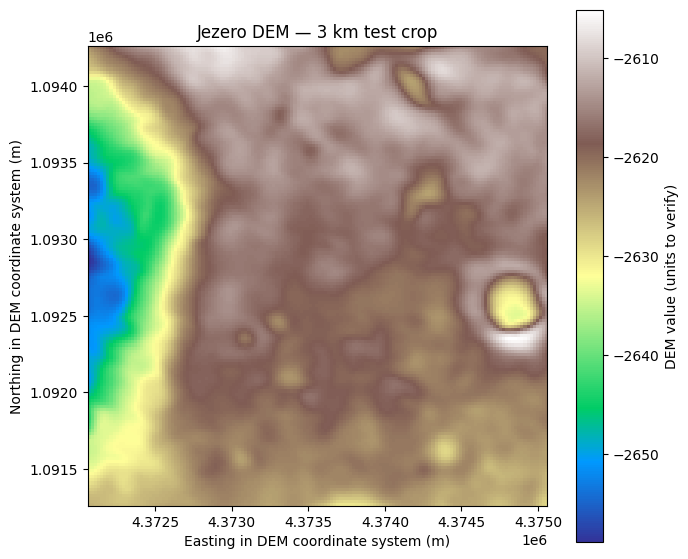

Saved crop:    /content/drive/MyDrive/Marswalk/Processed data/jezero_test_corridor_dem.tif
Saved preview: /content/drive/MyDrive/Marswalk/Outputs/jezero_test_corridor_dem.png
Crop bounds:   left=4372060, bottom=1091260, right=4375060, top=1094260


In [4]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.windows import Window

dem_path = RAW_DATA_DIR / "M20_JezeroCrater_CTXDEM_20m.tif"
crop_path = PROCESSED_DATA_DIR / "jezero_test_corridor_dem.tif"
preview_path = OUTPUTS_DIR / "jezero_test_corridor_dem.png"

crop_pixels = 150  # 150 pixels × 20 m/pixel = 3 km

with rasterio.open(dem_path) as src:
    row = (src.height - crop_pixels) // 2
    col = (src.width - crop_pixels) // 2
    window = Window(col, row, crop_pixels, crop_pixels)

    data = src.read(1, window=window)
    transform = src.window_transform(window)

    profile = src.profile.copy()
    profile.update(
        height=crop_pixels,
        width=crop_pixels,
        transform=transform,
        compress="deflate",
    )

    with rasterio.open(crop_path, "w", **profile) as dst:
        dst.write(data, 1)
        dst.update_tags(
            source_file=dem_path.name,
            note="Center test crop; not a selected science site."
        )

    nodata = src.nodata
    valid = np.isfinite(data)
    if nodata is not None:
        valid &= data != nodata

    left = transform.c
    top = transform.f
    right = left + crop_pixels * transform.a
    bottom = top + crop_pixels * transform.e

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(
    np.ma.array(data, mask=~valid),
    extent=(left, right, bottom, top),
    origin="upper",
    cmap="terrain",
)
ax.set_title("Jezero DEM — 3 km test crop")
ax.set_xlabel("Easting in DEM coordinate system (m)")
ax.set_ylabel("Northing in DEM coordinate system (m)")
fig.colorbar(image, ax=ax, label="DEM value (units to verify)")
fig.tight_layout()
fig.savefig(preview_path, dpi=160)
plt.show()

print(f"Saved crop:    {crop_path}")
print(f"Saved preview: {preview_path}")
print(f"Crop bounds:   left={left:.0f}, bottom={bottom:.0f}, right={right:.0f}, top={top:.0f}")

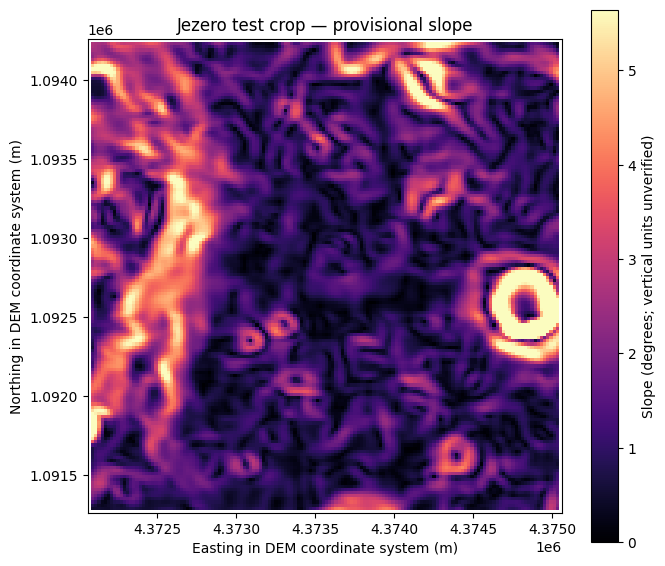

Saved slope raster: /content/drive/MyDrive/Marswalk/Processed data/jezero_test_corridor_slope.tif
Saved slope preview: /content/drive/MyDrive/Marswalk/Outputs/jezero_test_corridor_slope.png
Provisional slope percentiles (degrees): [0.0, 1.21, 3.6, 5.65, 19.62]
Reminder: verify the DEM's vertical units before using slope values as mission constraints.


In [5]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from scipy.ndimage import convolve, minimum_filter

dem_path = PROCESSED_DATA_DIR / "jezero_test_corridor_dem.tif"
slope_path = PROCESSED_DATA_DIR / "jezero_test_corridor_slope.tif"
preview_path = OUTPUTS_DIR / "jezero_test_corridor_slope.png"

with rasterio.open(dem_path) as src:
    elevation = src.read(1).astype(np.float32)
    nodata = src.nodata
    dx = abs(src.transform.a)
    dy = abs(src.transform.e)
    valid = np.isfinite(elevation)
    if nodata is not None:
        valid &= elevation != nodata

    # Apply the raster's declared scale and offset.
    elevation = elevation * src.scales[0] + src.offsets[0]

    # Horn 3x3 terrain-gradient kernels.
    kernel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1],
    ], dtype=np.float32) / (8 * dx)

    kernel_y = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1],
    ], dtype=np.float32) / (8 * dy)

    # Ignore invalid pixels while calculating, then mask any 3x3
    # neighborhood that touches nodata or the raster edge.
    filled = np.where(valid, elevation, 0)
    dz_dx = convolve(filled, kernel_x, mode="constant", cval=0)
    dz_dy = convolve(filled, kernel_y, mode="constant", cval=0)
    slope_degrees = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))

    complete_neighborhood = minimum_filter(
        valid.astype(np.uint8), size=3, mode="constant", cval=0
    ).astype(bool)
    slope_valid = complete_neighborhood & np.isfinite(slope_degrees)

    slope_nodata = -9999.0
    slope_output = np.where(slope_valid, slope_degrees, slope_nodata).astype(np.float32)

    # Don't carry over source tiling/block settings into this small output.
    profile = src.profile.copy()
    for key in ("blockxsize", "blockysize", "tiled", "predictor"):
        profile.pop(key, None)
    profile.update(
        dtype="float32",
        count=1,
        nodata=slope_nodata,
        compress="deflate",
    )

    with rasterio.open(slope_path, "w", **profile) as dst:
        dst.write(slope_output, 1)
        dst.set_band_description(1, "Provisional slope in degrees")
        dst.update_tags(
            method="Horn 3x3 gradient",
            horizontal_units="metres, from raster CRS",
            vertical_units="unverified; confirm before interpreting slope degrees",
            source_file=dem_path.name,
        )

values = slope_output[slope_valid]
if values.size == 0:
    raise ValueError("No valid slope pixels were calculated.")

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(
    np.ma.array(slope_output, mask=~slope_valid),
    extent=(left, right, bottom, top),
    origin="upper",
    cmap="magma",
    vmin=0,
    vmax=np.percentile(values, 98),
)
ax.set_title("Jezero test crop — provisional slope")
ax.set_xlabel("Easting in DEM coordinate system (m)")
ax.set_ylabel("Northing in DEM coordinate system (m)")
fig.colorbar(image, ax=ax, label="Slope (degrees; vertical units unverified)")
fig.tight_layout()
fig.savefig(preview_path, dpi=160)
plt.show()

print(f"Saved slope raster: {slope_path}")
print(f"Saved slope preview: {preview_path}")
print(
    "Provisional slope percentiles (degrees):",
    np.percentile(values, [0, 50, 90, 98, 100]).round(2).tolist()
)
print("Reminder: verify the DEM's vertical units before using slope values as mission constraints.")

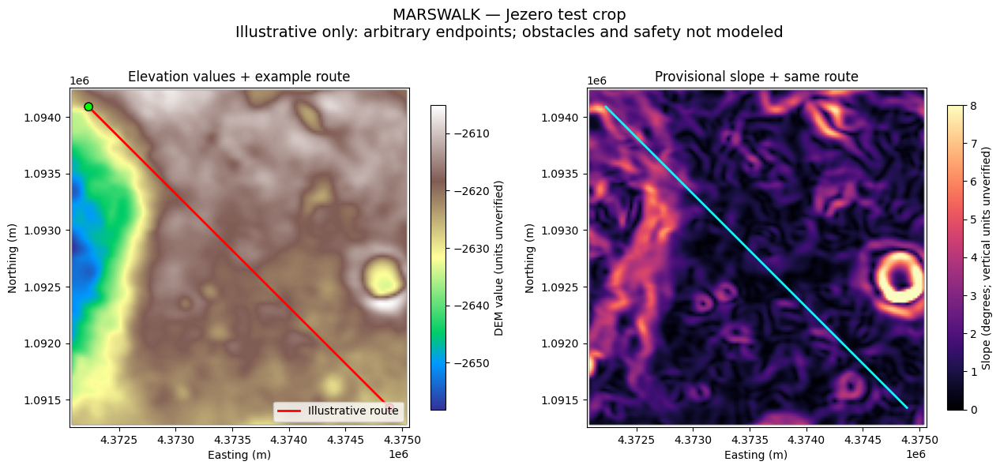

Saved static demo map: /content/drive/MyDrive/Marswalk/Outputs/marswalk_static_demo.png
Example path length: 134 grid cells


In [6]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.csgraph import dijkstra

dem_path = PROCESSED_DATA_DIR / "jezero_test_corridor_dem.tif"
slope_path = PROCESSED_DATA_DIR / "jezero_test_corridor_slope.tif"
map_path = OUTPUTS_DIR / "marswalk_static_demo.png"

with rasterio.open(dem_path) as dem_src, rasterio.open(slope_path) as slope_src:
    dem = dem_src.read(1).astype(float)
    slope = slope_src.read(1).astype(float)
    transform = dem_src.transform
    dem_nodata = dem_src.nodata
    slope_nodata = slope_src.nodata

valid = np.isfinite(dem) & np.isfinite(slope)
if dem_nodata is not None:
    valid &= dem != dem_nodata
if slope_nodata is not None:
    valid &= slope != slope_nodata

rows, cols = dem.shape
node_id = np.arange(rows * cols).reshape(rows, cols)
graph = lil_matrix((rows * cols, rows * cols), dtype=np.float32)

# Illustrative cost: distance × (1 + mean slope / 20°).
# This is not a validated route-planning or safety model.
for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1),
               (-1, -1), (-1, 1), (1, -1), (1, 1)):
    r0, r1 = max(0, -dr), min(rows, rows - dr)
    c0, c1 = max(0, -dc), min(cols, cols - dc)
    rr, cc = np.mgrid[r0:r1, c0:c1]
    nr, nc = rr + dr, cc + dc
    ok = valid[rr, cc] & valid[nr, nc]

    distance_m = 20.0 * (np.sqrt(2) if dr and dc else 1.0)
    cost = distance_m * (1 + (slope[rr, cc] + slope[nr, nc]) / 40.0)

    graph[node_id[rr[ok], cc[ok]], node_id[nr[ok], nc[ok]]] = cost[ok]

# Arbitrary test-crop endpoints; snap each to the nearest valid pixel.
valid_rc = np.argwhere(valid)
def nearest_valid(target_row, target_col):
    distances = (valid_rc[:, 0] - target_row)**2 + (valid_rc[:, 1] - target_col)**2
    return tuple(valid_rc[np.argmin(distances)])

start = nearest_valid(8, 8)
goal = nearest_valid(rows - 9, cols - 9)

distances, predecessors = dijkstra(
    graph.tocsr(),
    directed=True,
    indices=node_id[start],
    return_predecessors=True,
)

target = node_id[goal]
if not np.isfinite(distances[target]):
    raise RuntimeError("No path found across valid DEM pixels; try different endpoints.")

path_ids = [target]
while path_ids[-1] != node_id[start]:
    previous = predecessors[path_ids[-1]]
    if previous < 0:
        raise RuntimeError("Could not reconstruct the example path.")
    path_ids.append(previous)

path_ids.reverse()
path_rows, path_cols = np.unravel_index(path_ids, (rows, cols))

# Map pixel centers into the DEM's projected coordinates.
xs = transform.c + (path_cols + 0.5) * transform.a
ys = transform.f + (path_rows + 0.5) * transform.e
extent = (
    transform.c,
    transform.c + cols * transform.a,
    transform.f + rows * transform.e,
    transform.f,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

dem_plot = axes[0].imshow(
    np.ma.masked_where(~valid, dem),
    extent=extent, origin="upper", cmap="terrain"
)
axes[0].plot(xs, ys, color="red", linewidth=2, label="Illustrative route")
axes[0].scatter([xs[0], xs[-1]], [ys[0], ys[-1]], c=["lime", "red"],
                edgecolor="black", s=55, zorder=3)
axes[0].set_title("Elevation values + example route")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
axes[0].legend(loc="lower right")
fig.colorbar(dem_plot, ax=axes[0], shrink=0.75, label="DEM value (units unverified)")

slope_plot = axes[1].imshow(
    np.ma.masked_where(~valid, slope),
    extent=extent, origin="upper", cmap="magma", vmin=0, vmax=8
)
axes[1].plot(xs, ys, color="cyan", linewidth=2)
axes[1].set_title("Provisional slope + same route")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
fig.colorbar(slope_plot, ax=axes[1], shrink=0.75,
             label="Slope (degrees; vertical units unverified)")

fig.suptitle(
    "MARSWALK — Jezero test crop\n"
    "Illustrative only: arbitrary endpoints; obstacles and safety not modeled",
    fontsize=14,
)
fig.tight_layout()
fig.savefig(map_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved static demo map: {map_path}")
print(f"Example path length: {len(path_rows)} grid cells")

In [7]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output
from scipy.sparse import lil_matrix
from scipy.sparse.csgraph import dijkstra

dem_path = PROCESSED_DATA_DIR / "jezero_test_corridor_dem.tif"
slope_path = PROCESSED_DATA_DIR / "jezero_test_corridor_slope.tif"
map_path = OUTPUTS_DIR / "marswalk_prototype.png"

# Load the small test rasters.
with rasterio.open(dem_path) as src:
    dem = src.read(1).astype(float)
    transform = src.transform
    dem_nodata = src.nodata
    raster_crs = str(src.crs)

with rasterio.open(slope_path) as src:
    slope = src.read(1).astype(float)
    slope_nodata = src.nodata

valid = np.isfinite(dem) & np.isfinite(slope)
if dem_nodata is not None:
    valid &= dem != dem_nodata
if slope_nodata is not None:
    valid &= slope != slope_nodata

rows, cols = dem.shape
if not valid.any():
    raise ValueError("No valid pixels found in the test rasters.")

def nearest_valid(row, col):
    points = np.argwhere(valid)
    i = np.argmin((points[:, 0] - row)**2 + (points[:, 1] - col)**2)
    return tuple(points[i])

def plan_and_draw(_=None):
    with output:
        clear_output(wait=True)

        start = nearest_valid(start_row.value, start_col.value)
        goal = nearest_valid(end_row.value, end_col.value)
        max_slope = slope_limit.value

        # Demo-only routing cost. The cutoff is a user-selected display
        # parameter, not a validated astronaut/suit safety limit.
        graph = lil_matrix((rows * cols, rows * cols), dtype=np.float32)
        ids = np.arange(rows * cols).reshape(rows, cols)

        allowed = valid & (slope <= max_slope)
        if not allowed[start] or not allowed[goal]:
            print("Start or destination exceeds the selected slope cutoff. Increase it and re-plan.")
            return

        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1),
                       (-1, -1), (-1, 1), (1, -1), (1, 1)):
            r0, r1 = max(0, -dr), min(rows, rows - dr)
            c0, c1 = max(0, -dc), min(cols, cols - dc)
            rr, cc = np.mgrid[r0:r1, c0:c1]
            nr, nc = rr + dr, cc + dc

            ok = allowed[rr, cc] & allowed[nr, nc]
            step_m = 20 * (np.sqrt(2) if dr and dc else 1)
            edge_cost = step_m * (
                1 + (slope[rr, cc] + slope[nr, nc]) / 40
            )
            graph[ids[rr[ok], cc[ok]], ids[nr[ok], nc[ok]]] = edge_cost[ok]

        start_id, goal_id = ids[start], ids[goal]
        distances, predecessors = dijkstra(
            graph.tocsr(), directed=True, indices=start_id,
            return_predecessors=True
        )

        if not np.isfinite(distances[goal_id]):
            print("No route found under this slope cutoff. Try increasing it.")
            return

        path = [goal_id]
        while path[-1] != start_id:
            previous = predecessors[path[-1]]
            if previous < 0:
                print("Could not reconstruct route.")
                return
            path.append(previous)
        path.reverse()
        pr, pc = np.unravel_index(path, (rows, cols))

        # Approximate map coordinates from the raster transform.
        px = transform.c + (pc + 0.5) * transform.a
        py = transform.f + (pr + 0.5) * transform.e
        extent = (
            transform.c,
            transform.c + cols * transform.a,
            transform.f + rows * transform.e,
            transform.f,
        )

        layer = dem if layer_choice.value == "Elevation" else slope
        cmap = "terrain" if layer_choice.value == "Elevation" else "magma"
        label = "DEM value (units unverified)" if layer_choice.value == "Elevation" else "Slope (degrees; vertical units unverified)"

        fig, ax = plt.subplots(figsize=(8, 7))
        im = ax.imshow(
            np.ma.masked_where(~valid, layer),
            extent=extent,
            origin="upper",
            cmap=cmap,
        )
        ax.plot(px, py, color="cyan", linewidth=2.5, label="Illustrative route")
        ax.scatter([px[0], px[-1]], [py[0], py[-1]],
                   c=["lime", "red"], edgecolor="black", s=65, zorder=3)
        ax.set_title(f"Marswalk prototype — {layer_choice.value}")
        ax.set_xlabel("Easting in DEM coordinate system (m)")
        ax.set_ylabel("Northing in DEM coordinate system (m)")
        ax.legend()
        fig.colorbar(im, ax=ax, label=label)
        fig.suptitle("Test crop · illustrative route · not a safety assessment")
        fig.tight_layout()
        fig.savefig(map_path, dpi=160, bbox_inches="tight")
        plt.show()

        step_lengths = np.hypot(np.diff(pr), np.diff(pc)) * 20
        route_length = float(step_lengths.sum())
        route_max_slope = float(np.max(slope[pr, pc]))
        print(f"Approximate route length: {route_length:.0f} m")
        print(f"Maximum sampled slope on route: {route_max_slope:.1f}° (provisional)")
        print(f"Map saved to: {map_path}")
        print(f"Raster CRS: {raster_crs}")

# Controls use pixel positions in this 150 × 150 test crop.
slider_layout = widgets.Layout(width="320px")
start_row = widgets.IntSlider(value=8, min=0, max=rows-1, description="Start row", layout=slider_layout)
start_col = widgets.IntSlider(value=8, min=0, max=cols-1, description="Start col", layout=slider_layout)
end_row = widgets.IntSlider(value=rows-9, min=0, max=rows-1, description="End row", layout=slider_layout)
end_col = widgets.IntSlider(value=cols-9, min=0, max=cols-1, description="End col", layout=slider_layout)
slope_limit = widgets.FloatSlider(
    value=10, min=1, max=20, step=0.5,
    description="Slope cutoff °", readout_format=".1f", layout=slider_layout
)
layer_choice = widgets.Dropdown(
    options=["Elevation", "Slope"], value="Elevation", description="Map layer:"
)
plan_button = widgets.Button(description="Plan / update route", button_style="primary")
output = widgets.Output()

plan_button.on_click(plan_and_draw)
display(widgets.VBox([
    widgets.HTML("<b>Marswalk — interactive prototype</b><br>"
                 "Adjust controls, then click Plan / update route."),
    layer_choice,
    start_row, start_col, end_row, end_col,
    slope_limit,
    plan_button,
    output,
]))
plan_and_draw()

In [8]:
import folium
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from folium.plugins import Fullscreen
from IPython.display import display
from scipy.sparse import lil_matrix
from scipy.sparse.csgraph import dijkstra

dem_path = PROCESSED_DATA_DIR / "jezero_test_corridor_dem.tif"
slope_path = PROCESSED_DATA_DIR / "jezero_test_corridor_slope.tif"
map_path = OUTPUTS_DIR / "marswalk_leaflet_map.html"

# Load the rasters.
with rasterio.open(dem_path) as src:
    dem = src.read(1).astype(float)
    dem_nodata = src.nodata
    rows, cols = dem.shape
    transform = src.transform

with rasterio.open(slope_path) as src:
    slope = src.read(1).astype(float)
    slope_nodata = src.nodata

valid = np.isfinite(dem) & np.isfinite(slope)
if dem_nodata is not None:
    valid &= dem != dem_nodata
if slope_nodata is not None:
    valid &= slope != slope_nodata
if not valid.any():
    raise ValueError("No valid pixels found in the DEM and slope rasters.")

# Convert data to embedded RGBA images; transparent pixels represent nodata.
def rgba_layer(data, cmap_name, vmin=None, vmax=None):
    vals = data[valid]
    norm = Normalize(
        vmin=float(np.min(vals)) if vmin is None else vmin,
        vmax=float(np.max(vals)) if vmax is None else vmax,
    )
    rgba = plt.get_cmap(cmap_name)(norm(np.where(valid, data, 0)))
    rgba[..., 3] = valid.astype(float) * 0.88
    return (rgba * 255).astype(np.uint8)

elevation_image = rgba_layer(dem, "terrain")
slope_image = rgba_layer(slope, "magma", vmin=0, vmax=8)

# Find a demonstration route, restricted by a provisional slope cutoff.
max_slope_demo = 10.0
allowed = valid & (slope <= max_slope_demo)
ids = np.arange(rows * cols).reshape(rows, cols)
graph = lil_matrix((rows * cols, rows * cols), dtype=np.float32)

for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1),
               (-1, -1), (-1, 1), (1, -1), (1, 1)):
    r0, r1 = max(0, -dr), min(rows, rows - dr)
    c0, c1 = max(0, -dc), min(cols, cols - dc)
    rr, cc = np.mgrid[r0:r1, c0:c1]
    nr, nc = rr + dr, cc + dc
    ok = allowed[rr, cc] & allowed[nr, nc]

    step = np.sqrt(2) if dr and dc else 1.0
    cost = step * (1 + (slope[rr, cc] + slope[nr, nc]) / 40)
    graph[ids[rr[ok], cc[ok]], ids[nr[ok], nc[ok]]] = cost[ok]

valid_points = np.argwhere(allowed)
if len(valid_points) == 0:
    raise ValueError("No pixels meet the provisional slope cutoff.")

def nearest_allowed(row, col):
    d2 = (valid_points[:, 0] - row)**2 + (valid_points[:, 1] - col)**2
    return tuple(valid_points[np.argmin(d2)])

start = nearest_allowed(8, 8)
goal = nearest_allowed(rows - 9, cols - 9)

distances, previous = dijkstra(
    graph.tocsr(), directed=True, indices=ids[start],
    return_predecessors=True
)
goal_id = ids[goal]
if not np.isfinite(distances[goal_id]):
    raise RuntimeError("No route found; try a higher provisional slope cutoff.")

path = [goal_id]
while path[-1] != ids[start]:
    parent = previous[path[-1]]
    if parent < 0:
        raise RuntimeError("Could not reconstruct the route.")
    path.append(parent)
path.reverse()
path_rows, path_cols = np.unravel_index(path, (rows, cols))

# Leaflet CRS.Simple coordinates use pixel units here.
# Negative row values keep image rows aligned with the overlay.
bounds = [[-rows, 0], [0, cols]]
route_points = [
    [-float(r + 0.5), float(c + 0.5)]
    for r, c in zip(path_rows, path_cols)
]

m = folium.Map(
    location=[-rows / 2, cols / 2],
    crs="Simple",
    tiles=None,
    zoom_start=0,
    min_zoom=-2,
    max_zoom=4,
    width="100%",
    height=650,
    control_scale=False,
)

folium.raster_layers.ImageOverlay(
    image=elevation_image,
    bounds=bounds,
    name="Elevation",
    opacity=0.9,
    interactive=True,
    cross_origin=False,
    zindex=1,
    show=True,
).add_to(m)

folium.raster_layers.ImageOverlay(
    image=slope_image,
    bounds=bounds,
    name="Provisional slope",
    opacity=0.85,
    interactive=True,
    cross_origin=False,
    zindex=2,
    show=False,
).add_to(m)

folium.PolyLine(
    route_points,
    color="#00e5ff",
    weight=4,
    tooltip="Illustrative route — not safety guidance",
).add_to(m)

folium.Marker(
    route_points[0],
    tooltip="Example start",
    popup="Illustrative start point in the test crop",
    icon=folium.Icon(color="green", icon="play"),
).add_to(m)

folium.Marker(
    route_points[-1],
    tooltip="Example destination",
    popup="Illustrative destination in the test crop",
    icon=folium.Icon(color="red", icon="flag"),
).add_to(m)

Fullscreen(position="topright").add_to(m)
m.fit_bounds(bounds, padding=[25, 25], max_zoom=1)

folium.Element("""
<div style="position:fixed;bottom:24px;left:50px;z-index:9999;
background:white;padding:10px 14px;border:1px solid #777;
border-radius:6px;max-width:340px;font:14px/1.4 Arial,sans-serif">
<b>Marswalk prototype</b><br>
Test crop and illustrative route. Slope is provisional; DEM vertical units
are unverified. Not mission or safety guidance.
</div>
""").add_to(m.get_root().html)

m.save(str(map_path))
print(f"Saved interactive map: {map_path}")
#display(m)

Saved interactive map: /content/drive/MyDrive/Marswalk/Outputs/marswalk_leaflet_map.html


In [9]:
import base64
from datetime import datetime, timezone
from html import escape

map_path = OUTPUTS_DIR / "marswalk_prototype.png"
html_path = OUTPUTS_DIR / "marswalk_demo.html"
readme_path = DOCUMENTATION_DIR / "README_demo.md"

if not map_path.is_file():
    raise FileNotFoundError(
        f"{map_path} not found. Run the interactive planner and generate a map first."
    )

image_data = base64.b64encode(map_path.read_bytes()).decode("ascii")
generated = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

html_content = f"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Marswalk — Jezero prototype</title>
<style>
  body {{ margin: 0; background: #eceee8; color: #1d2733;
          font: 16px/1.6 system-ui, sans-serif; }}
  main {{ max-width: 1000px; margin: auto; padding: 28px 20px 56px; }}
  h1 {{ margin-bottom: 4px; }}
  .note {{ padding: 14px 18px; border-left: 5px solid #c0367a;
           background: #fff; margin: 18px 0; }}
  img {{ display: block; width: 100%; height: auto; background: white; }}
  .muted {{ color: #58636f; }}
</style>
</head>
<body>
<main>
<h1>Marswalk: Jezero route-planning prototype</h1>
<p class="muted">A notebook prototype using a 20 m CTX DEM test crop. Generated {escape(generated)}.</p>
<img src="data:image/png;base64,{image_data}" alt="Elevation or slope map with an illustrative route">
<div class="note">
<strong>Prototype, not mission guidance.</strong>
The displayed crop is a centered test area, not a verified science site.
The example route uses a simplified, user-selected slope cutoff. The DEM's
vertical units have not been verified. This prototype does not model obstacles,
radiation, weather, suit mobility, or astronaut safety.
</div>
<h2>Data and provenance</h2>
<p>The input raster is
<code>M20_JezeroCrater_CTXDEM_20m.tif</code> from this project's Raw data folder.
Record its original product citation, provider, download URL, and license in the
project documentation before presenting it as a sourced NASA product. Other
challenge references (Mars Trek, USGS–NASA geologic maps, Perseverance images,
and the Curiosity route animation) are planned research sources or design
references; they are not represented as layers in this map.</p>
<h2>What the prototype demonstrates</h2>
<ul>
<li>Loads a georeferenced Mars DEM crop and derived provisional slope raster.</li>
<li>Lets the user select endpoints, a displayed layer, and a slope cutoff in Colab.</li>
<li>Computes and visualizes an illustrative route over valid raster cells.</li>
</ul>
</main>
</body>
</html>
"""

html_path.write_text(html_content, encoding="utf-8")

readme_content = f"""# Marswalk — prototype demo

## Run
Open the Colab notebook and run the setup, raster processing, and interactive
planner cells. Adjust the controls and click **Plan / update route**. Run the
packaging cell to refresh `Outputs/marswalk_demo.html`.

## Current prototype
- Input: `Raw data/M20_JezeroCrater_CTXDEM_20m.tif`
- Test crop: `Processed data/jezero_test_corridor_dem.tif`
- Provisional slope: `Processed data/jezero_test_corridor_slope.tif`
- Interactive map image: `Outputs/marswalk_prototype.png`
- Shareable demo: `Outputs/marswalk_demo.html`

## Important limitations
The crop is centered for testing and is not a verified science site. Vertical
units have not been confirmed. The route and slope cutoff are illustrative;
this is not a validated safety or mission-planning tool. Obstacles, radiation,
weather, and suit mobility are not modeled.

## Source follow-up
Document the original DEM product citation, provider, download URL, and license.
Do not imply that reference portals or example videos are data layers unless
specific products from them are actually included.
"""
readme_path.write_text(readme_content, encoding="utf-8")

print(f"Shareable demo: {html_path}")
print(f"Project notes:  {readme_path}")
print("Download marswalk_demo.html from Google Drive to share the standalone demo.")

Shareable demo: /content/drive/MyDrive/Marswalk/Outputs/marswalk_demo.html
Project notes:  /content/drive/MyDrive/Marswalk/Documentation/README_demo.md
Download marswalk_demo.html from Google Drive to share the standalone demo.


In [10]:
# Replace your existing Gradio frontend cell with this one.
# Run it after the setup, crop, and slope cells have completed.

import sys
import subprocess
import importlib.util

if importlib.util.find_spec("gradio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])

import gradio as gr
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from scipy.sparse import lil_matrix
from scipy.sparse.csgraph import dijkstra
from PIL import Image
import io

dem_path = PROCESSED_DATA_DIR / "jezero_test_corridor_dem.tif"
slope_path = PROCESSED_DATA_DIR / "jezero_test_corridor_slope.tif"

# Load the demo rasters.
with rasterio.open(dem_path) as src:
    dem = src.read(1).astype(float)
    transform = src.transform
    dem_nodata = src.nodata
    pixel_size = abs(src.transform.a)

with rasterio.open(slope_path) as src:
    slope = src.read(1).astype(float)
    slope_nodata = src.nodata

valid = np.isfinite(dem) & np.isfinite(slope)
if dem_nodata is not None:
    valid &= dem != dem_nodata
if slope_nodata is not None:
    valid &= slope != slope_nodata

rows, cols = dem.shape
if not valid.any():
    raise ValueError("No valid pixels found in the demo rasters.")

# Hillshade is derived from the DEM; it is a visualization layer,
# not an independent dataset. Vertical units are unverified.
hillshade = LightSource(azdeg=315, altdeg=45).hillshade(
    np.ma.array(dem, mask=~valid),
    vert_exag=1,
    dx=pixel_size,
    dy=pixel_size,
)

def make_map(start_row, start_col, end_row, end_col, max_slope, layer):
    allowed = valid & (slope <= max_slope)
    candidates = np.argwhere(allowed)

    if len(candidates) == 0:
        return None, "No valid terrain at this cutoff. Increase the slope cutoff."

    def snap(row, col):
        distances = (
            (candidates[:, 0] - int(row))**2
            + (candidates[:, 1] - int(col))**2
        )
        return tuple(candidates[np.argmin(distances)])

    start = snap(start_row, start_col)
    goal = snap(end_row, end_col)

    # Illustrative route cost: distance penalized by provisional slope.
    graph = lil_matrix((rows * cols, rows * cols), dtype=np.float32)
    ids = np.arange(rows * cols).reshape(rows, cols)

    for dr, dc in (
        (-1, 0), (1, 0), (0, -1), (0, 1),
        (-1, -1), (-1, 1), (1, -1), (1, 1)
    ):
        r0, r1 = max(0, -dr), min(rows, rows - dr)
        c0, c1 = max(0, -dc), min(cols, cols - dc)
        rr, cc = np.mgrid[r0:r1, c0:c1]
        nr, nc = rr + dr, cc + dc

        ok = allowed[rr, cc] & allowed[nr, nc]
        step = pixel_size * (np.sqrt(2) if dr and dc else 1)
        cost = step * (1 + (slope[rr, cc] + slope[nr, nc]) / 40)
        graph[ids[rr[ok], cc[ok]], ids[nr[ok], nc[ok]]] = cost[ok]

    start_id, goal_id = ids[start], ids[goal]
    distances, previous = dijkstra(
        graph.tocsr(),
        directed=True,
        indices=start_id,
        return_predecessors=True,
    )

    if not np.isfinite(distances[goal_id]):
        return None, "No route found. Try increasing the slope cutoff."

    path = [goal_id]
    while path[-1] != start_id:
        parent = previous[path[-1]]
        if parent < 0:
            return None, "Could not reconstruct a route. Try different endpoints."
        path.append(parent)
    path.reverse()

    path_rows, path_cols = np.unravel_index(path, (rows, cols))
    x = transform.c + (path_cols + 0.5) * transform.a
    y = transform.f + (path_rows + 0.5) * transform.e

    extent = (
        transform.c,
        transform.c + cols * transform.a,
        transform.f + rows * transform.e,
        transform.f,
    )

    if layer == "Elevation":
        image_data = np.ma.array(dem, mask=~valid)
        cmap = "terrain"
        colorbar_label = "DEM value (units unverified)"
    elif layer == "Slope":
        image_data = np.ma.array(slope, mask=~valid)
        cmap = "magma"
        colorbar_label = "Slope (degrees; vertical units unverified)"
    else:
        image_data = np.ma.array(hillshade, mask=~valid)
        cmap = "gray"
        colorbar_label = "Relative illumination (qualitative)"

    fig, ax = plt.subplots(figsize=(8, 6))
    plotted = ax.imshow(
        image_data,
        extent=extent,
        origin="upper",
        cmap=cmap,
    )
    ax.plot(x, y, color="cyan", linewidth=2.5, label="Illustrative route")
    ax.scatter(
        [x[0], x[-1]], [y[0], y[-1]],
        c=["lime", "red"], edgecolor="black", s=60, zorder=3,
    )
    ax.set_title(f"Jezero test crop — {layer}")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.legend()

    fig.colorbar(plotted, ax=ax, label=colorbar_label)
    fig.suptitle("Prototype only — not a safety assessment")
    fig.tight_layout()

    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    plt.close(fig)
    buffer.seek(0)
    result_image = Image.open(buffer).copy()

    route_length_m = np.hypot(
        np.diff(path_rows), np.diff(path_cols)
    ).sum() * pixel_size
    max_route_slope = float(np.max(slope[path_rows, path_cols]))

    note = (
        f"Approximate route length: **{route_length_m:.0f} m**  \n"
        f"Maximum sampled slope: **{max_route_slope:.1f}° (provisional)**  \n\n"
        "**Limitations:** centered test crop; vertical units unverified; "
        "obstacles, radiation, weather, suit mobility, and astronaut safety "
        "are not modeled. Hillshade is derived from the DEM."
    )
    return result_image, note

with gr.Blocks(title="Marswalk — Jezero prototype") as app:
    gr.Markdown(
        "# 🪐 Marswalk — Jezero prototype\n"
        "Select a map layer and generate an illustrative route. "
        "**This is not mission guidance or a safety assessment.**"
    )

    with gr.Row():
        layer = gr.Dropdown(
            ["Elevation", "Slope", "Hillshade"],
            value="Elevation",
            label="Map layer",
        )
        slope_limit = gr.Slider(
            1, 20, value=10, step=0.5,
            label="Illustrative slope cutoff (°)",
        )

    with gr.Row():
        start_row = gr.Slider(0, rows - 1, value=8, step=1, label="Start row")
        start_col = gr.Slider(0, cols - 1, value=8, step=1, label="Start column")

    with gr.Row():
        end_row = gr.Slider(
            0, rows - 1, value=rows - 9, step=1, label="Destination row"
        )
        end_col = gr.Slider(
            0, cols - 1, value=cols - 9, step=1, label="Destination column"
        )

    button = gr.Button("Plan / update route", variant="primary")
    map_output = gr.Image(label="Prototype map")
    note_output = gr.Markdown()

    button.click(
        fn=make_map,
        inputs=[start_row, start_col, end_row, end_col, slope_limit, layer],
        outputs=[map_output, note_output],
    )

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cd9942e699ca19fea9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [11]:
import folium
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize, LightSource
from folium.plugins import Fullscreen
from IPython.display import display

dem_path = RAW_DATA_DIR / "M20_JezeroCrater_CTXDEM_20m.tif"
map_path = OUTPUTS_DIR / "marswalk_jezero_movable_map.html"

# Read a reduced-resolution overview of the full DEM for a faster web map.
max_dimension = 1200

with rasterio.open(dem_path) as src:
    scale = min(1.0, max_dimension / max(src.height, src.width))
    height = max(1, round(src.height * scale))
    width = max(1, round(src.width * scale))

    dem_small = src.read(
        1,
        out_shape=(height, width),
        masked=True,
        resampling=rasterio.enums.Resampling.average,
    ).astype(np.float32)

    crs_text = str(src.crs)

valid = ~np.ma.getmaskarray(dem_small) & np.isfinite(dem_small.data)
values = dem_small.data[valid]

if values.size == 0:
    raise ValueError("No valid DEM pixels found.")

# Use the full raster's downsampled pixel coordinates for the web map.
# This is a local Jezero view, not a global Mars coordinate system.
bounds = [[-height, 0], [0, width]]
center = [-height / 2, width / 2]

# Colorized elevation layer.
norm = Normalize(vmin=float(np.percentile(values, 2)),
                 vmax=float(np.percentile(values, 98)))
elevation_rgba = plt.get_cmap("terrain")(norm(np.where(valid, dem_small.data, values.min())))
elevation_rgba[..., 3] = valid.astype(float) * 0.95
elevation_rgba = (elevation_rgba * 255).astype(np.uint8)

# Shaded relief, derived from this same DEM.
filled = np.where(valid, dem_small.data, np.nanmedian(values))
hillshade = LightSource(azdeg=315, altdeg=45).hillshade(
    filled,
    vert_exag=1,
    dx=1,
    dy=1,
)
hill_rgba = plt.get_cmap("gray")(hillshade)
hill_rgba[..., 3] = valid.astype(float) * 0.9
hill_rgba = (hill_rgba * 255).astype(np.uint8)

m = folium.Map(
    location=center,
    crs="Simple",
    tiles=None,
    zoom_start=0,
    min_zoom=-2,
    max_zoom=4,
    width="100%",
    height=700,
    control_scale=False,
)

folium.raster_layers.ImageOverlay(
    image=elevation_rgba,
    bounds=bounds,
    name="Elevation",
    opacity=0.95,
    interactive=True,
    cross_origin=False,
    show=True,
).add_to(m)

folium.raster_layers.ImageOverlay(
    image=hill_rgba,
    bounds=bounds,
    name="Hillshade (derived from DEM)",
    opacity=0.9,
    interactive=True,
    cross_origin=False,
    show=False,
).add_to(m)

Fullscreen(position="topright").add_to(m)
folium.LatLngPopup().add_to(m)
m.fit_bounds(bounds, padding=[20, 20], max_zoom=1)

folium.Element(f"""
<div style="position:fixed;bottom:24px;left:50px;z-index:9999;
background:white;padding:10px 14px;border:1px solid #777;
border-radius:6px;max-width:380px;font:14px/1.4 Arial,sans-serif">
<b>Marswalk — Jezero DEM overview</b><br>
Pan and zoom within the coverage of the input DEM. Click the map to inspect
local display coordinates. Hillshade is derived from the same DEM.
DEM vertical units are unverified; this is not mission or safety guidance.
</div>
""").add_to(m.get_root().html)

m.save(str(map_path))
print(f"Saved movable map: {map_path}")
print(f"Showing downsampled overview: {width} × {height} pixels")
print(f"Source CRS: {crs_text}")
#display(m)

Saved movable map: /content/drive/MyDrive/Marswalk/Outputs/marswalk_jezero_movable_map.html
Showing downsampled overview: 1055 × 1200 pixels
Source CRS: PROJCS["Jezero_Crater_Projection",GEOGCS["GCS_Mars_2000_Sphere",DATUM["Mars_2000_(Sphere)",SPHEROID["Mars_2000_Sphere",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",18.4663],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


In [12]:
from pathlib import Path
from urllib.request import urlopen, Request
from zipfile import ZipFile, BadZipFile

zip_path = RAW_DATA_DIR / "usgs_jezero_geology_sim3464.zip"
extract_dir = RAW_DATA_DIR / "USGS_SIM3464"

# Corrected URL from sim3464_gis.zip to sim3464_database.zip
url = "https://pubs.usgs.gov/sim/3464/sim3464_database.zip"

# Download only if the archive isn't already present.
if not zip_path.exists():
    print("Downloading the USGS Jezero geology GIS archive (~349 MB)...")
    request = Request(url, headers={"User-Agent": "MarswalkColabPrototype/1.0"})
    with urlopen(request, timeout=60) as response, zip_path.open("wb") as out:
        total = int(response.headers.get("Content-Length", 0))
        downloaded = 0

        while True:
            chunk = response.read(1024 * 1024)
            if not chunk:
                break
            out.write(chunk)
            downloaded += len(chunk)
            if total:
                print(f"\rDownloaded {downloaded / total:.0%}", end="")

    print("\nDownload complete.")
else:
    print(f"Using existing archive: {zip_path}")

# Extract once, and prevent archive paths from writing outside the target folder.
extract_dir.mkdir(parents=True, exist_ok=True)
root = extract_dir.resolve()

try:
    with ZipFile(zip_path) as archive:
        members = archive.infolist()
        for member in members:
            destination = (extract_dir / member.filename).resolve()
            if destination != root and root not in destination.parents:
                raise ValueError(f"Unsafe archive path: {member.filename}")
        archive.extractall(extract_dir)
except BadZipFile as exc:
    raise RuntimeError(f"The downloaded file is not a valid ZIP: {zip_path}") from exc

vector_files = []
for pattern in ("*.shp", "*.gpkg", "*.geojson", "*.gdb"):
    vector_files.extend(extract_dir.rglob(pattern))

print(f"\nExtracted to: {extract_dir}")
if vector_files:
    print("Vector datasets found:")
    for path in vector_files:
        print(f"- {path.relative_to(extract_dir)}")
else:
    print("No common vector files found. Please share the extracted file listing.")

Using existing archive: /content/drive/MyDrive/Marswalk/Raw data/usgs_jezero_geology_sim3464.zip

Extracted to: /content/drive/MyDrive/Marswalk/Raw data/USGS_SIM3464
Vector datasets found:
- sim3464_JezeroNili_FINAL/Geodatabase/Nili.gdb


In [13]:
import sys
import subprocess
import importlib.util
from pathlib import Path

if importlib.util.find_spec("fiona") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "fiona"])

import fiona

# Search within the Marswalk project folder for the geodatabase directory.
gdb_matches = list(PROJECT_ROOT.rglob("Nili.gdb"))

if not gdb_matches:
    raise FileNotFoundError(
        f"Could not find Nili.gdb under {PROJECT_ROOT}. "
        "Make sure the geodatabase folder is inside your Marswalk Drive folder."
    )

gdb_path = gdb_matches[0]
print(f"Geodatabase found: {gdb_path}")
print("\nLayers:")

for layer_name in fiona.listlayers(str(gdb_path)):
    with fiona.open(str(gdb_path), layer=layer_name) as layer:
        print(f"\n- {layer_name}")
        print(f"  Feature count: {len(layer)}")
        print(f"  CRS: {layer.crs_wkt or layer.crs}")
        print(f"  Bounds: {layer.bounds}")
        print(f"  Geometry: {layer.schema.get('geometry')}")
        print(f"  Fields: {list(layer.schema.get('properties', {}).keys())}")

Geodatabase found: /content/drive/MyDrive/Marswalk/Raw data/USGS_SIM3464/sim3464_JezeroNili_FINAL/Geodatabase/Nili.gdb

Layers:



- MapBoundary
  Feature count: 1
  CRS: PROJCS["MTM_clon77.5E",GEOGCS["Mars_2000_(Sphere)",DATUM["Mars_2000_(Sphere)",SPHEROID["Mars_2000_(Sphere)",3396190,0],AUTHORITY["ESRI","106971"]],PRIMEM["Reference_Meridian",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",77.5],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["Meter",1],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
  Bounds: (-39528.90637077391, 1049162.14616251, 16940.67943917215, 1108513.8212197945)
  Geometry: MultiPolygon
  Fields: ['Shape_Length', 'Shape_Area', 'QUAD_NAME']

- Nomenclature
  Feature count: 10
  CRS: PROJCS["MTM_clon77.5E",GEOGCS["Mars_2000_(Sphere)",DATUM["Mars_2000_(Sphere)",SPHEROID["Mars_2000_(Sphere)",3396190,0],AUTHORITY["ESRI","106971"]],PRIMEM["Reference_Meridian",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARA

Reading GeoUnits_v1 and transforming it to the DEM CRS...


Features in GeoUnits_v1: 1304
Features overlapping the DEM: 1021
DEM bounds in its CRS: BoundingBox(left=4328999.999999998, bottom=1042080.0000000028, right=4418119.999999998, top=1143420.0000000028)
Rasterizing geology polygons onto the DEM grid...


/tmp/ipykernel_724/3004570182.py:144: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(rgba, mode="RGBA").save(overlay_path)


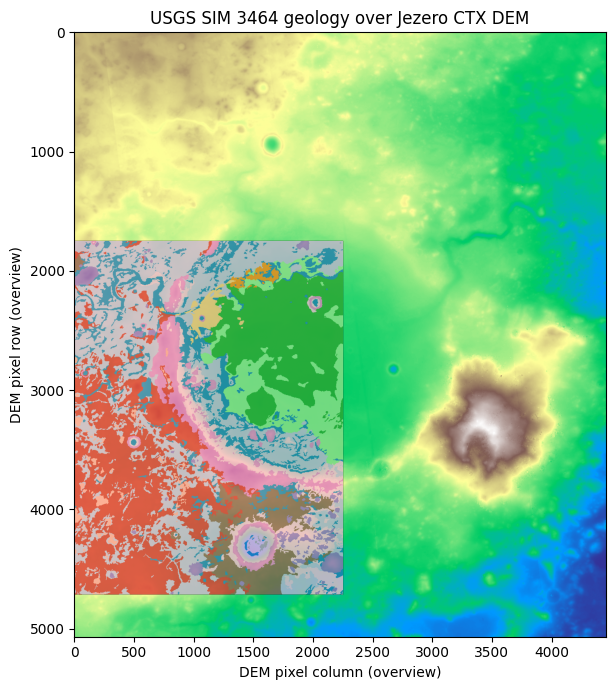

Geology raster: /content/drive/MyDrive/Marswalk/Processed data/jezero_geology_units.tif
Leaflet overlay PNG: /content/drive/MyDrive/Marswalk/Outputs/jezero_geology_overlay.png
Legend: /content/drive/MyDrive/Marswalk/Outputs/jezero_geology_legend.csv
Quicklook: /content/drive/MyDrive/Marswalk/Outputs/jezero_geology_quicklook.png
Geology-covered DEM pixels: 6,686,784


In [14]:
import sys
import subprocess
import importlib.util
from pathlib import Path

if importlib.util.find_spec("geopandas") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geopandas"])

import geopandas as gpd
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from PIL import Image
from rasterio.features import rasterize
from shapely.geometry import box

gdb_path = (
    RAW_DATA_DIR
    / "USGS_SIM3464"
    / "sim3464_JezeroNili_FINAL"
    / "Geodatabase"
    / "Nili.gdb"
)
dem_path = RAW_DATA_DIR / "M20_JezeroCrater_CTXDEM_20m.tif"

geology_raster_path = PROCESSED_DATA_DIR / "jezero_geology_units.tif"
overlay_path = OUTPUTS_DIR / "jezero_geology_overlay.png"
preview_path = OUTPUTS_DIR / "jezero_geology_quicklook.png"
legend_path = OUTPUTS_DIR / "jezero_geology_legend.csv"

if not gdb_path.exists():
    raise FileNotFoundError(f"Geodatabase not found: {gdb_path}")

print("Reading GeoUnits_v1 and transforming it to the DEM CRS...")
geology = gpd.read_file(str(gdb_path), layer="GeoUnits_v1", engine="fiona")

with rasterio.open(dem_path) as dem_src:
    dem_crs = dem_src.crs
    dem_transform = dem_src.transform
    dem_bounds = dem_src.bounds
    dem_width, dem_height = dem_src.width, dem_src.height
    dem_profile = dem_src.profile.copy()

    max_dimension = 1200
    scale = min(1.0, max_dimension / max(dem_height, dem_width))
    display_height = max(1, round(dem_height * scale))
    display_width = max(1, round(dem_width * scale))
    dem_preview = dem_src.read(
        1,
        out_shape=(display_height, display_width),
        resampling=rasterio.enums.Resampling.average,
        masked=True,
    )

if geology.crs is None:
    raise ValueError("GeoUnits_v1 has no CRS metadata; stop rather than guess its projection.")

geology = geology.to_crs(dem_crs)
geology = geology[geology.geometry.notna() & ~geology.geometry.is_empty].copy()

# Confirm that reprojected polygons overlap the DEM before rasterizing.
dem_box = box(dem_bounds.left, dem_bounds.bottom, dem_bounds.right, dem_bounds.top)
overlapping = geology[geology.geometry.intersects(dem_box)].copy()

print(f"Features in GeoUnits_v1: {len(geology)}")
print(f"Features overlapping the DEM: {len(overlapping)}")
print(f"DEM bounds in its CRS: {dem_bounds}")

if overlapping.empty:
    raise ValueError(
        "No geology polygons overlap the DEM after reprojection. "
        "Do not add this layer until the CRS definitions are checked."
    )

# Use the geologic unit symbol as the category; fall back to unit/name.
def get_category(row):
    for field in ("symbol", "unit", "name"):
        value = row.get(field)
        if value is not None and str(value).strip() and str(value).lower() != "nan":
            return str(value).strip()
    return "Unlabeled unit"

overlapping["map_category"] = overlapping.apply(get_category, axis=1)
categories = sorted(overlapping["map_category"].unique())
category_to_id = {category: i + 1 for i, category in enumerate(categories)}

shapes = [
    (geom, category_to_id[category])
    for geom, category in zip(overlapping.geometry, overlapping["map_category"])
]

print("Rasterizing geology polygons onto the DEM grid...")
geology_ids = rasterize(
    shapes=shapes,
    out_shape=(dem_height, dem_width),
    transform=dem_transform,
    fill=0,
    dtype="uint16",
    all_touched=False,
)

covered_pixels = int(np.count_nonzero(geology_ids))
if covered_pixels == 0:
    raise ValueError(
        "Reprojected polygons intersect the DEM bounds but rasterize to no pixels. "
        "Check the coordinate transformation and map coverage."
    )

# Save a categorical GeoTIFF aligned exactly with the source DEM.
for key in ("blockxsize", "blockysize", "tiled", "predictor"):
    dem_profile.pop(key, None)
dem_profile.update(
    count=1,
    dtype="uint16",
    nodata=0,
    compress="deflate",
)

with rasterio.open(geology_raster_path, "w", **dem_profile) as dst:
    dst.write(geology_ids, 1)
    dst.set_band_description(1, "USGS SIM 3464 geologic unit category ID")
    dst.update_tags(
        source="USGS SIM 3464, GeoUnits_v1 layer",
        alignment="Reprojected to and rasterized on the CTX DEM grid",
        category_field="symbol, with unit/name fallback",
    )

# Make a transparent PNG the same reduced size as the full-DEM Leaflet overview.
small_ids = np.asarray(
    Image.fromarray(geology_ids).resize(
        (display_width, display_height),
        resample=Image.Resampling.NEAREST,
    )
)

palette = plt.get_cmap("tab20")
rgba = np.zeros((display_height, display_width, 4), dtype=np.uint8)
for category, category_id in category_to_id.items():
    color = np.array(palette((category_id - 1) % 20)) * 255
    rgba[small_ids == category_id] = color.astype(np.uint8)
    rgba[small_ids == category_id, 3] = 190  # partial transparency

Image.fromarray(rgba, mode="RGBA").save(overlay_path)

# Save a category legend so map colors can be explained.
with open(legend_path, "w", encoding="utf-8") as f:
    f.write("category_id,geologic_unit\n")
    for category, category_id in category_to_id.items():
        safe_category = category.replace('"', '""')
        f.write(f'{category_id},"{safe_category}"\n')

# Show the geology overlay on the downsampled DEM for an alignment check.
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(dem_preview, extent=(0, dem_width, dem_height, 0), cmap="terrain")
ax.imshow(rgba, extent=(0, dem_width, dem_height, 0))
ax.set_title("USGS SIM 3464 geology over Jezero CTX DEM")
ax.set_xlabel("DEM pixel column (overview)")
ax.set_ylabel("DEM pixel row (overview)")
fig.tight_layout()
fig.savefig(preview_path, dpi=150)
plt.show()

print(f"Geology raster: {geology_raster_path}")
print(f"Leaflet overlay PNG: {overlay_path}")
print(f"Legend: {legend_path}")
print(f"Quicklook: {preview_path}")
print(f"Geology-covered DEM pixels: {covered_pixels:,}")

In [15]:
import csv
import json
import numpy as np
import rasterio
import geopandas as gpd
import folium
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.colors import Normalize, LightSource
from folium.plugins import Fullscreen
from IPython.display import display
from shapely.geometry import box, mapping
from shapely.ops import transform as transform_geometry

dem_path = RAW_DATA_DIR / "M20_JezeroCrater_CTXDEM_20m.tif"
geology_raster_path = PROCESSED_DATA_DIR / "jezero_geology_units.tif"
gdb_path = (
    RAW_DATA_DIR / "USGS_SIM3464" / "sim3464_JezeroNili_FINAL"
    / "Geodatabase" / "Nili.gdb"
)
legend_csv = OUTPUTS_DIR / "jezero_geology_legend.csv"
html_path = OUTPUTS_DIR / "marswalk_jezero_final.html"

# Read a reduced-resolution overview for a responsive web map.
max_dimension = 1200
with rasterio.open(dem_path) as src:
    dem_crs = src.crs
    dem_transform = src.transform
    dem_bounds = src.bounds
    dem_width, dem_height = src.width, src.height
    dem_nodata = src.nodata

    factor = min(1.0, max_dimension / max(dem_height, dem_width))
    view_height = max(1, round(dem_height * factor))
    view_width = max(1, round(dem_width * factor))

    dem_view = src.read(
        1,
        out_shape=(view_height, view_width),
        masked=True,
        resampling=rasterio.enums.Resampling.average,
    ).astype(np.float32)

with rasterio.open(geology_raster_path) as src:
    geology_view = src.read(
        1,
        out_shape=(view_height, view_width),
        resampling=rasterio.enums.Resampling.nearest,
    )

dem_data = dem_view.filled(np.nan)
valid = np.isfinite(dem_data)
if dem_nodata is not None:
    valid &= dem_data != dem_nodata
values = dem_data[valid]
if values.size == 0:
    raise ValueError("No valid DEM pixels found.")

# Read category names saved by the geology-preparation cell.
with open(legend_csv, newline="", encoding="utf-8") as f:
    legend_rows = list(csv.DictReader(f))

id_to_unit = {
    int(row["category_id"]): row["geologic_unit"]
    for row in legend_rows
}
max_unit_id = max(id_to_unit, default=0)

# Create an elevation image and a transparent geology image as NumPy arrays.
elev_norm = Normalize(
    vmin=float(np.percentile(values, 2)),
    vmax=float(np.percentile(values, 98)),
)
elev_rgba = plt.get_cmap("terrain")(
    elev_norm(np.where(valid, dem_data, np.nanmin(values)))
)
elev_rgba[..., 3] = valid * 0.95
elev_rgba_uint8 = (elev_rgba * 255).astype(np.uint8)

palette = plt.get_cmap("tab20")
geo_rgba = np.zeros((view_height, view_width, 4), dtype=np.uint8)
for unit_id in id_to_unit:
    mask = geology_view == unit_id
    color = (np.array(palette((unit_id - 1) % 20)) * 255).astype(np.uint8)
    geo_rgba[mask, :3] = color[:3]
    geo_rgba[mask, 3] = 190

# Create hillshade from the DEM for visual relief; it is not a separate dataset.
filled_dem = np.where(valid, dem_data, np.nanmedian(values))
shade = LightSource(azdeg=315, altdeg=45).hillshade(
    filled_dem, vert_exag=1, dx=1, dy=1
)
shade_rgba = plt.get_cmap("gray")(shade)
shade_rgba[..., 3] = valid * 0.9
shade_rgba_uint8 = (shade_rgba * 255).astype(np.uint8)

# Use pixel-like coordinates in Leaflet's simple CRS.
bounds = [[-view_height, 0], [0, view_width]]
center = [-view_height / 2, view_width / 2]

m = folium.Map(
    location=center,
    crs="Simple",
    tiles=None,
    zoom_start=0,
    min_zoom=-2,
    max_zoom=4,
    width="100%",
    height=720,
    control_scale=False,
)
folium.raster_layers.ImageOverlay(
    image=elev_rgba_uint8, bounds=bounds, name="Elevation",
    opacity=0.95, show=True,
).add_to(m)
folium.raster_layers.ImageOverlay(
    image=geo_rgba, bounds=bounds, name="USGS geology units",
    opacity=0.8, show=False,
).add_to(m)
folium.raster_layers.ImageOverlay(
    image=shade_rgba_uint8, bounds=bounds, name="Hillshade (derived)",
    opacity=0.8, show=False,
).add_to(m)

# Add clickable/hoverable geology polygons. Their geometry is transformed
# from the DEM's projected coordinates into this map's pixel coordinates.
geology = gpd.read_file(str(gdb_path), layer="GeoUnits_v1", engine="fiona")
if geology.crs is None:
    raise ValueError("GeoUnits_v1 has no CRS metadata; cannot align it safely.")

geology = geology.to_crs(dem_crs)
dem_box = box(
    dem_bounds.left, dem_bounds.bottom, dem_bounds.right, dem_bounds.top
)
geology = geology[
    geology.geometry.notna()
    & ~geology.geometry.is_empty
    & geology.geometry.intersects(dem_box)
].copy()

def unit_name(row):
    for field in ("symbol", "unit", "name"):
        value = row.get(field)
        if value is not None and str(value).strip() and str(value).lower() != "nan":
            return str(value).strip()
    return "Unlabeled geologic unit"

# Convert projected DEM coordinates to display pixels.
inverse = ~dem_transform
scale_x = view_width / dem_width
scale_y = view_height / dem_height

def to_map_pixels(x, y, z=None):
    col, row = inverse * (x, y)
    x_out = col * scale_x
    y_out = -row * scale_y
    return (x_out, y_out) if z is None else (x_out, y_out, z)

features = []
for _, row in geology.iterrows():
    geom = row.geometry.intersection(dem_box)
    if geom.is_empty:
        continue
    geom = geom.simplify(100, preserve_topology=True)
    geom = transform_geometry(to_map_pixels, geom)
    features.append({
        "type": "Feature",
        "geometry": mapping(geom),
        "properties": {"unit": unit_name(row)},
    })

geojson = {"type": "FeatureCollection", "features": features}
if features:
    folium.GeoJson(
        geojson,
        name="Clickable geology boundaries",
        style_function=lambda feature: {
            "color": "#ffffff",
            "weight": 1,
            "opacity": 0.55,
            "fillColor": "#ffffff",
            "fillOpacity": 0.01,
        },
        tooltip=folium.GeoJsonTooltip(
            fields=["unit"],
            aliases=["Geologic unit:"],
            sticky=True,
        ),
        popup=folium.GeoJsonPopup(
            fields=["unit"],
            aliases=["Geologic unit:"],
            labels=True,
        ),
        show=True,
    ).add_to(m)

Fullscreen(position="topright").add_to(m)
folium.LatLngPopup().add_to(m)
m.fit_bounds(bounds, padding=[20, 20], max_zoom=1)

# Compact map notes and source attribution.
notice = """
<div style="position:fixed;bottom:24px;left:50px;z-index:9999;
background:#fff;padding:10px 14px;border:1px solid #777;border-radius:6px;
max-width:390px;font:14px/1.45 Arial,sans-serif">
<b>Marswalk · Jezero explorer</b><br>
Toggle layers at top right. Hover or click geology polygons for unit names.
Hillshade is derived from the DEM. DEM vertical units are unverified.
Prototype route/safety planning is not modeled here.
</div>
"""
folium.Element(notice).add_to(m.get_root().html)

m.save(str(html_path))
print(f"Saved final interactive map: {html_path}")
print(f"Geology polygons available for hover/click: {len(features)}")
#display(m)

/tmp/ipykernel_724/710785109.py:166: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  geom = transform_geometry(to_map_pixels, geom)


Saved final interactive map: /content/drive/MyDrive/Marswalk/Outputs/marswalk_jezero_final.html
Geology polygons available for hover/click: 1021


In [16]:
import rasterio
from pyproj import CRS, Transformer

dem_path = RAW_DATA_DIR / "M20_JezeroCrater_CTXDEM_20m.tif"

with rasterio.open(dem_path) as src:
    mars_crs = CRS.from_wkt(src.crs.to_wkt())
    geographic_crs = mars_crs.geodetic_crs

    if geographic_crs is None:
        raise ValueError("Could not identify the DEM's Mars geographic CRS.")

    to_mars_lonlat = Transformer.from_crs(
        mars_crs, geographic_crs, always_xy=True
    )

    b = src.bounds
    corners = {
        "lower-left": (b.left, b.bottom),
        "lower-right": (b.right, b.bottom),
        "upper-left": (b.left, b.top),
        "upper-right": (b.right, b.top),
    }

    print("Geographic CRS from DEM:", geographic_crs.name)
    print("DEM corner coordinates (longitude, latitude):")
    for name, (x, y) in corners.items():
        lon, lat = to_mars_lonlat.transform(x, y)
        print(f"  {name}: {lon:.4f}°, {lat:.4f}°")

print("\nThese are transformed DEM coordinates, not the Leaflet click-popup values.")

Geographic CRS from DEM: GCS_Mars_2000_Sphere
DEM corner coordinates (longitude, latitude):
  lower-left: 76.9974°, 17.5805°
  lower-right: 78.5826°, 17.5805°
  upper-left: 76.9974°, 19.2902°
  upper-right: 78.5826°, 19.2902°

These are transformed DEM coordinates, not the Leaflet click-popup values.


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import minimum_filter
import folium
from IPython.display import display

# Uses the downsampled DEM and map bounds created by the final map cell.
if "dem_data" not in globals() or "valid" not in globals() or "m" not in globals():
    raise RuntimeError(
        "Run the final map cell first; it defines the DEM overview and Leaflet map."
    )

filled = np.where(valid, dem_data, np.nanmedian(dem_data[valid]))

# Approximate overview pixel spacing from the source DEM's projected pixel size.
dx = abs(dem_transform.a) * dem_width / view_width
dy = abs(dem_transform.e) * dem_height / view_height

# Provisional slope: assumes DEM vertical values are meters, which is not yet verified.
gradient_y, gradient_x = np.gradient(filled, dy, dx)
slope_degrees = np.degrees(np.arctan(np.hypot(gradient_x, gradient_y)))

# Exclude nodata edges from display.
valid_neighborhood = minimum_filter(
    valid.astype(np.uint8), size=3, mode="constant", cval=0
).astype(bool)

# Categories describe only calculated slope—not safety.
# 1: <=5°, 2: >5° to 10°, 3: >10°
rgba = np.zeros((*slope_degrees.shape, 4), dtype=np.uint8)
colors = {
    1: (46, 160, 90, 190),    # green
    2: (242, 180, 55, 190),   # amber
    3: (205, 65, 65, 210),    # red
}

for category, color in colors.items():
    if category == 1:
        mask = valid_neighborhood & (slope_degrees <= 5)
    elif category == 2:
        mask = valid_neighborhood & (slope_degrees > 5) & (slope_degrees <= 10)
    else:
        mask = valid_neighborhood & (slope_degrees > 10)

    rgba[mask] = color

# Fixed: Pass the NumPy RGBA array directly to avoid the PIL Image serialization error
folium.raster_layers.ImageOverlay(
    image=rgba,
    bounds=bounds,
    name="Provisional slope screening — NOT safety",
    opacity=0.85,
    interactive=True,
    cross_origin=False,
    show=False,
).add_to(m)


# Prominent explanation for anyone viewing the map.
folium.Element("""
<div style="position:fixed;top:12px;left:50px;z-index:9999;
background:white;padding:10px 14px;border:1px solid #777;border-radius:6px;
max-width:390px;font:14px/1.45 Arial,sans-serif">
<b>Terrain screening only—not a safety rating.</b><br>
Green: calculated slope ≤5°; amber: 5–10°; red: &gt;10°.
Thresholds are illustrative, DEM vertical units are unverified, and this layer
does not assess obstacles, radiation, weather, or suit mobility.
</div>
""").add_to(m.get_root().html)

html_path = OUTPUTS_DIR / "marswalk_jezero_final.html"
m.save(str(html_path))

print(f"Updated interactive map: {html_path}")
print("Enable the slope-screening layer using the layer control.")
#display(m)

Updated interactive map: /content/drive/MyDrive/Marswalk/Outputs/marswalk_jezero_final.html
Enable the slope-screening layer using the layer control.


In [18]:
# Run after the Drive setup and geology-preparation cells.
# This replaces the previous final-map and slope-overlay cells.

import geopandas as gpd
import folium
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.colors import Normalize, LightSource
from folium.plugins import Fullscreen
from IPython.display import display
from shapely.geometry import box, mapping
from shapely.ops import transform as transform_geometry

dem_path = RAW_DATA_DIR / "M20_JezeroCrater_CTXDEM_20m.tif"
geology_raster_path = PROCESSED_DATA_DIR / "jezero_geology_units.tif"
gdb_path = (
    RAW_DATA_DIR / "USGS_SIM3464" / "sim3464_JezeroNili_FINAL"
    / "Geodatabase" / "Nili.gdb"
)
html_path = OUTPUTS_DIR / "marswalk_jezero_final.html"

# Load a downsampled full-DEM view so the browser map stays responsive.
max_dimension = 1200
with rasterio.open(dem_path) as src:
    dem_crs = src.crs
    dem_transform = src.transform
    dem_bounds = src.bounds
    dem_width, dem_height = src.width, src.height
    dem_nodata = src.nodata

    factor = min(1.0, max_dimension / max(dem_height, dem_width))
    view_height = max(1, round(dem_height * factor))
    view_width = max(1, round(dem_width * factor))

    dem_masked = src.read(
        1,
        out_shape=(view_height, view_width),
        masked=True,
        resampling=rasterio.enums.Resampling.average,
    ).astype(np.float32)

    dem_units = src.tags(1)

dem = dem_masked.filled(np.nan)
valid = np.isfinite(dem)
if dem_nodata is not None:
    valid &= dem != dem_nodata
if not valid.any():
    raise ValueError("No valid DEM pixels found.")
dem_values = dem[valid]

# Read geology categories from the raster already aligned to the DEM.
with rasterio.open(geology_raster_path) as src:
    geology_ids = src.read(
        1,
        out_shape=(view_height, view_width),
        resampling=rasterio.enums.Resampling.nearest,
    )

legend_csv = OUTPUTS_DIR / "jezero_geology_legend.csv"
unit_names = {}
if legend_csv.exists():
    import csv
    with open(legend_csv, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            unit_names[int(row["category_id"])] = row["geologic_unit"]

# Leaflet Simple CRS coordinates are local display pixels, not longitude/latitude.
map_bounds = [[-view_height, 0], [0, view_width]]
map_center = [-view_height / 2, view_width / 2]

# Elevation image.
elev_norm = Normalize(
    vmin=float(np.percentile(dem_values, 2)),
    vmax=float(np.percentile(dem_values, 98)),
)
elev_rgba = plt.get_cmap("terrain")(
    elev_norm(np.where(valid, dem, float(np.nanmin(dem_values))))
)
elev_rgba[..., 3] = valid.astype(float) * 0.96
elevation_array = (elev_rgba * 255).astype(np.uint8)

# Hillshade derived from this DEM.
filled_dem = np.where(valid, dem, float(np.nanmedian(dem_values)))
hillshade = LightSource(azdeg=315, altdeg=45).hillshade(
    filled_dem, vert_exag=1, dx=1, dy=1
)
hill_rgba = plt.get_cmap("gray")(hillshade)
hill_rgba[..., 3] = valid.astype(float) * 0.95
hillshade_array = (hill_rgba * 255).astype(np.uint8)

# Calculate provisional slope for visual screening only.
# Vertical units are unverified, so this is not a safety rating.
dx = abs(dem_transform.a) * dem_width / view_width
dy = abs(dem_transform.e) * dem_height / view_height
filled_for_gradient = np.where(valid, dem, np.nanmedian(dem_values))
grad_y, grad_x = np.gradient(filled_for_gradient, dy, dx)
slope_degrees = np.degrees(np.arctan(np.hypot(grad_x, grad_y)))

slope_rgba = np.zeros((view_height, view_width, 4), dtype=np.uint8)
slope_rgba[valid & (slope_degrees <= 5)] = (46, 160, 90, 200)
slope_rgba[valid & (slope_degrees > 5) & (slope_degrees <= 10)] = (242, 180, 55, 205)
slope_rgba[valid & (slope_degrees > 10)] = (205, 65, 65, 215)

# Categorical geology image, transparent where no geology polygon was rasterized.
geo_rgba = np.zeros((view_height, view_width, 4), dtype=np.uint8)
for unit_id in sorted(int(v) for v in np.unique(geology_ids) if v > 0):
    color = (np.array(plt.get_cmap("tab20")((unit_id - 1) % 20)) * 255).astype(np.uint8)
    mask = (geology_ids == unit_id) & valid
    geo_rgba[mask, :3] = color[:3]
    geo_rgba[mask, 3] = 190

# Build map and add every toggleable layer BEFORE creating LayerControl.
m = folium.Map(
    location=map_center,
    crs="Simple",
    tiles=None,
    zoom_start=0,
    min_zoom=-2,
    max_zoom=4,
    width="100%",
    height=720,
    control_scale=False,
)

folium.raster_layers.ImageOverlay(
    image=elevation_array, bounds=map_bounds, name="Elevation",
    opacity=0.95, show=True,
).add_to(m)

folium.raster_layers.ImageOverlay(
    image=hillshade_array, bounds=map_bounds, name="Hillshade (derived)",
    opacity=0.85, show=False,
).add_to(m)

folium.raster_layers.ImageOverlay(
    image=geo_rgba, bounds=map_bounds, name="USGS geology units",
    opacity=0.80, show=False,
).add_to(m)

folium.raster_layers.ImageOverlay(
    image=slope_rgba, bounds=map_bounds,
    name="Provisional slope screening — not safety",
    opacity=0.85, show=False,
).add_to(m)

# Add clickable geology polygons and unit labels.
geology = gpd.read_file(str(gdb_path), layer="GeoUnits_v1", engine="fiona")
if geology.crs is None:
    raise ValueError("GeoUnits_v1 has no CRS metadata; cannot align it safely.")
geology = geology.to_crs(dem_crs)

dem_box = box(
    dem_bounds.left, dem_bounds.bottom, dem_bounds.right, dem_bounds.top
)
geology = geology[
    geology.geometry.notna()
    & ~geology.geometry.is_empty
    & geology.geometry.intersects(dem_box)
].copy()

def unit_label(row):
    for field in ("symbol", "unit", "name"):
        value = row.get(field)
        if value is not None and str(value).strip() and str(value).lower() != "nan":
            return str(value).strip()
    return "Unlabeled geologic unit"

inverse_transform = ~dem_transform
scale_x = view_width / dem_width
scale_y = view_height / dem_height

def to_map_pixels(x, y, z=None):
    col, row = inverse_transform * (x, y)
    px, py = col * scale_x, -row * scale_y
    return (px, py) if z is None else (px, py, z)

features = []
for _, row in geology.iterrows():
    geom = row.geometry.intersection(dem_box)
    if geom.is_empty:
        continue
    geom = geom.simplify(100, preserve_topology=True)
    geom = transform_geometry(to_map_pixels, geom)
    features.append({
        "type": "Feature",
        "geometry": mapping(geom),
        "properties": {"unit": unit_label(row)},
    })

if features:
    folium.GeoJson(
        {"type": "FeatureCollection", "features": features},
        name="Clickable geology boundaries",
        style_function=lambda feature: {
            "color": "#273444",
            "weight": 1,
            "opacity": 0.7,
            "fillOpacity": 0,
        },
        tooltip=folium.GeoJsonTooltip(
            fields=["unit"], aliases=["Geologic unit:"], sticky=True
        ),
        popup=folium.GeoJsonPopup(
            fields=["unit"], aliases=["Geologic unit:"], labels=True
        ),
        show=False,
    ).add_to(m)

# Add the layer control LAST so it includes all layers above.
Fullscreen(position="topright").add_to(m)

folium.Element("""
<div style="position:fixed;bottom:22px;left:50px;z-index:9999;
background:#fff;padding:10px 14px;border:1px solid #777;border-radius:6px;
max-width:410px;font:14px/1.45 Arial,sans-serif">
<b>Marswalk · Jezero terrain explorer</b><br>
Use the layer menu at top right to toggle elevation, hillshade, geology,
and provisional slope. Click geology boundaries for unit names.<br>
Slope bands are illustrative only—not a safety rating. DEM vertical units
are unverified. Radiation, weather, obstacles, and suit mobility are not modeled.
Map click coordinates are local display pixels, not longitude/latitude.
</div>
""").add_to(m.get_root().html)

m.fit_bounds(map_bounds, padding=[20, 20], max_zoom=1)
m.save(str(html_path))

print(f"Saved interactive map: {html_path}")
print(f"Geology boundary features: {len(features)}")
print("Map layers: Elevation, Hillshade, USGS geology units, provisional slope, clickable geology boundaries")
#display(m)

/tmp/ipykernel_724/3634680869.py:187: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  geom = transform_geometry(to_map_pixels, geom)


Saved interactive map: /content/drive/MyDrive/Marswalk/Outputs/marswalk_jezero_final.html
Geology boundary features: 1021
Map layers: Elevation, Hillshade, USGS geology units, provisional slope, clickable geology boundaries


Saved image:    /content/drive/MyDrive/Marswalk/Raw data/PIA25917_hollowed_rock.jpg
Saved metadata: /content/drive/MyDrive/Marswalk/Outputs/PIA25917_metadata.json
NASA ID: PIA25917
Title: Perseverance Finds a Hollowed-Out Rock
Sol: 836
Instrument: Mastcam-Z
Image URL: https://images-assets.nasa.gov/image/PIA25917/PIA25917~medium.jpg
Metadata URL: https://images-assets.nasa.gov/image/PIA25917/metadata.json


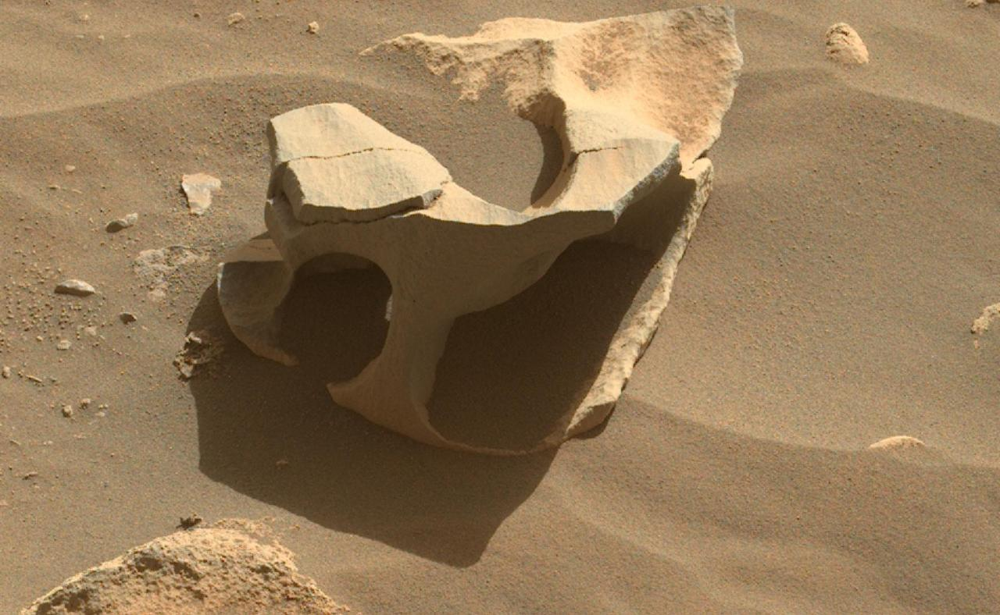

In [19]:
import json
from io import BytesIO

import requests
from PIL import Image
from IPython.display import display

image_url = "https://images-assets.nasa.gov/image/PIA25917/PIA25917~medium.jpg"
metadata_url = "https://images-assets.nasa.gov/image/PIA25917/metadata.json"

# Download and save the image for offline use in the project.
response = requests.get(image_url, timeout=30)
response.raise_for_status()

image_path = RAW_DATA_DIR / "PIA25917_hollowed_rock.jpg"
image_path.write_bytes(response.content)

# Fetch NASA asset metadata for title, description, and any listed credits.
meta_response = requests.get(metadata_url, timeout=30)
meta_response.raise_for_status()
asset_metadata = meta_response.json()

metadata_path = OUTPUTS_DIR / "PIA25917_metadata.json"
metadata_path.write_text(
    json.dumps(asset_metadata, indent=2),
    encoding="utf-8",
)

print(f"Saved image:    {image_path}")
print(f"Saved metadata: {metadata_path}")
print("NASA ID: PIA25917")
print("Title: Perseverance Finds a Hollowed-Out Rock")
print("Sol: 836")
print("Instrument: Mastcam-Z")
print("Image URL:", image_url)
print("Metadata URL:", metadata_url)

display(Image.open(BytesIO(response.content)))

In [20]:
import base64
import html
from pathlib import Path
from IPython.display import display

image_path = RAW_DATA_DIR / "PIA25917_hollowed_rock.jpg"
html_path = OUTPUTS_DIR / "marswalk_jezero_final.html"

if "m" not in globals():
    raise RuntimeError("Run the final interactive map cell first; it creates the map variable m.")
if not image_path.is_file():
    raise FileNotFoundError(
        f"Image not found: {image_path}. Run the image-download cell first."
    )

encoded_image = base64.b64encode(image_path.read_bytes()).decode("ascii")

title = html.escape("Perseverance Finds a Hollowed-Out Rock")
description = html.escape(
    "Mastcam-Z image from Jezero Crater, sol 836. "
    "Context image only; its location is not plotted on this map."
)
source_url = "https://images.nasa.gov/details/PIA25917"

photo_card = f"""
<div style="
 position:fixed; top:auto; right:12px; bottom:52px; left:auto;
 z-index:9999; width:260px; max-height:40vh; overflow:auto;
 background:#fff; border:1px solid #536273; border-radius:9px;
 padding:10px; box-shadow:0 2px 8px #0005;
 font:13px/1.45 Arial,sans-serif;">
 <b>{title}</b>
 <img src="data:image/jpeg;base64,{encoded_image}"
      alt="{title}, captured by Perseverance"
      style="display:block;width:100%;height:auto;margin:8px 0;border-radius:5px;">
 <div>{description}</div>
 <div style="margin-top:7px">
   <a href="{source_url}" target="_blank" rel="noopener">
     NASA image record · PIA25917
   </a>
 </div>
</div>
"""

folium.Element(photo_card).add_to(m.get_root().html)
m.save(str(html_path))

print(f"Updated interactive map: {html_path}")
#display(m)

Updated interactive map: /content/drive/MyDrive/Marswalk/Outputs/marswalk_jezero_final.html


In [21]:
from pathlib import Path
import subprocess
import sys

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Marswalk")
RAW_DIR = PROJECT_DIR / "Raw data"

if not RAW_DIR.exists():
    raise FileNotFoundError(
        f"Can't find {RAW_DIR}. Update RAW_DIR to your Drive folder containing the files."
    )

# Find the HiRISE DTM and the MEDA CSVs wherever they are under Raw data.
dtm_matches = list(RAW_DIR.rglob("DTEEC_023524_1985_023379_1985_U01.IMG"))
ps_matches = list(RAW_DIR.rglob("WE*DER_PS*.csv"))
tirs_matches = list(RAW_DIR.rglob("WE*DER_TIRS*.csv"))
rhs_matches = list(RAW_DIR.rglob("WE*DER_RHS*.csv"))

def show_matches(label, matches):
    print(f"\n{label}:")
    if matches:
        for path in matches[:10]:
            print(" ", path)
    else:
        print("  Not found under Raw data.")

show_matches("HiRISE DTM", dtm_matches)
show_matches("MEDA pressure (PS)", ps_matches)
show_matches("MEDA thermal infrared (TIRS)", tirs_matches)
show_matches("MEDA humidity (RHS)", rhs_matches)

# Try to open the DTM and report its real raster metadata.
if dtm_matches:
    dtm_path = dtm_matches[0]
    print(f"\n--- HiRISE DTM inspection: {dtm_path.name} ---")

    try:
        import rasterio
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
        import rasterio

    try:
        with rasterio.open(dtm_path) as src:
            print("Driver:", src.driver)
            print("Dimensions (width × height):", src.width, "×", src.height)
            print("Band count:", src.count)
            print("Data type:", src.dtypes)
            print("CRS:", src.crs)
            print("Bounds:", src.bounds)
            print("Pixel size:", src.res)
            print("Nodata:", src.nodata)
            print("Raster tags:", src.tags())

            # Read a small sample for a quick validity check, not the full 700 MB raster.
            sample = src.read(
                1,
                out_shape=(min(300, src.height), min(300, src.width)),
                masked=True,
            )
            print("Sample elevation min/max:", sample.min(), sample.max())

    except Exception as exc:
        print("Rasterio could not open this .IMG directly:")
        print(type(exc).__name__ + ":", exc)
        print(
            "Please check the download folder for a matching .LBL label file "
            "or a product README; send me those filenames."
        )

    # Look for the existing regional CTX DEM so we can compare coverage.
    ctx_matches = list(RAW_DIR.rglob("*CTXDEM*20m*.tif"))
    if ctx_matches:
        print("\n--- Existing CTX DEM footprint ---")
        try:
            with rasterio.open(ctx_matches[0]) as ctx:
                print("File:", ctx_matches[0].name)
                print("CRS:", ctx.crs)
                print("Bounds:", ctx.bounds)
                print("Pixel size:", ctx.res)
        except Exception as exc:
            print("Could not inspect CTX DEM:", exc)

# Inspect MEDA CSV columns, time ranges, and a few rows.
try:
    import pandas as pd
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pandas"])
    import pandas as pd

for label, matches in [
    ("PS pressure", ps_matches),
    ("TIRS infrared", tirs_matches),
    ("RHS humidity", rhs_matches),
]:
    if not matches:
        continue

    path = matches[0]
    print(f"\n--- MEDA {label}: {path.name} ---")
    try:
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", list(df.columns))

        for time_col in ("LMST", "LTST"):
            if time_col in df.columns and len(df):
                print(f"{time_col} first/last:", df[time_col].iloc[0], "/", df[time_col].iloc[-1])

        print("First 3 rows:")
        print(df.head(3).to_string(index=False))
    except Exception as exc:
        print("Could not read CSV:", type(exc).__name__ + ":", exc)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

HiRISE DTM:
  /content/drive/MyDrive/Marswalk/Raw data/DTEEC_023524_1985_023379_1985_U01.IMG

MEDA pressure (PS):
  /content/drive/MyDrive/Marswalk/Raw data/WE__0001___________DER_PS__________________P02.csv

MEDA thermal infrared (TIRS):
  /content/drive/MyDrive/Marswalk/Raw data/WE__0001___________DER_TIRS________________P04.csv

MEDA humidity (RHS):
  /content/drive/MyDrive/Marswalk/Raw data/WE__0001___________DER_RHS_________________P03.csv

--- HiRISE DTM inspection: DTEEC_023524_1985_023379_1985_U01.IMG ---
Driver: PDS
Dimensions (width × height): 8235 × 21258
Band count: 1
Data type: ('float32',)
CRS: PROJCS["EQUIRECTANGULAR MARS",GEOGCS["GCS_MARS",DATUM["D_MARS",SPHEROID["MARS_localRadius",3394839.8133163,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_pa

HiRISE source CRS: PROJCS["EQUIRECTANGULAR MARS",GEOGCS["GCS_MARS",DATUM["D_MARS",SPHEROID["MARS_localRadius",3394839.8133163,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",15],PARAMETER["central_meridian",77.53],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
HiRISE source pixel size: (1.0096633268711, 1.0096633268711)
CTX target CRS: PROJCS["Jezero_Crater_Projection",GEOGCS["GCS_Mars_2000_Sphere",DATUM["Mars_2000_(Sphere)",SPHEROID["Mars_2000_Sphere",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",18.4663],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Nor

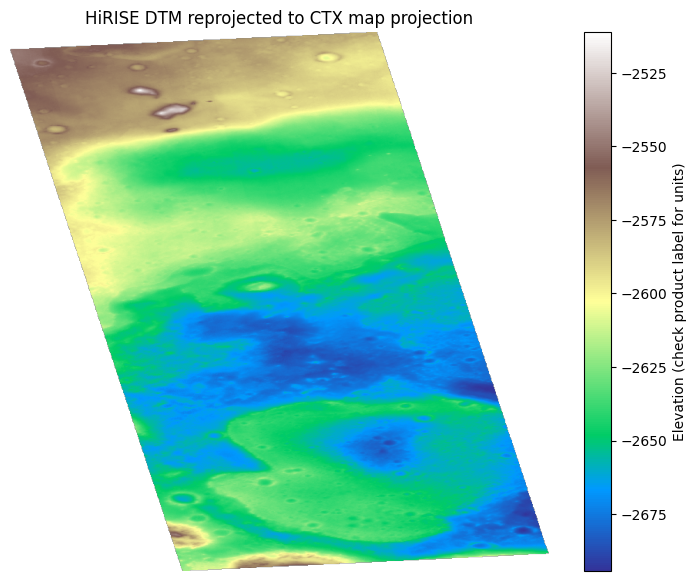

In [22]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.transform import from_bounds

project_dir = Path("/content/drive/MyDrive/Marswalk")
raw_dir = project_dir / "Raw data"
output_dir = project_dir / "Outputs"
output_dir.mkdir(parents=True, exist_ok=True)

hirise_path = raw_dir / "DTEEC_023524_1985_023379_1985_U01.IMG"
ctx_path = raw_dir / "M20_JezeroCrater_CTXDEM_20m.tif"
aligned_path = output_dir / "HiRISE_Jezero_DTM_in_CTX_CRS_5m.tif"

if not hirise_path.exists():
    raise FileNotFoundError(f"HiRISE DTM not found: {hirise_path}")
if not ctx_path.exists():
    raise FileNotFoundError(f"CTX DEM not found: {ctx_path}")

target_resolution_m = 5.0

with rasterio.open(hirise_path) as hirise, rasterio.open(ctx_path) as ctx:
    if hirise.crs is None or ctx.crs is None:
        raise ValueError("One of the rasters has no CRS; we must not guess its projection.")

    print("HiRISE source CRS:", hirise.crs)
    print("HiRISE source pixel size:", hirise.res)
    print("CTX target CRS:", ctx.crs)

    # Convert the HiRISE footprint into the CTX projection, then clip to CTX coverage.
    transformed_bounds = transform_bounds(
        hirise.crs,
        ctx.crs,
        *hirise.bounds,
        densify_pts=41,
    )
    ctx_bounds = ctx.bounds

    left = max(transformed_bounds[0], ctx_bounds.left)
    bottom = max(transformed_bounds[1], ctx_bounds.bottom)
    right = min(transformed_bounds[2], ctx_bounds.right)
    top = min(transformed_bounds[3], ctx_bounds.top)

    print("\nHiRISE footprint transformed to CTX CRS:", transformed_bounds)
    print("CTX bounds:", ctx_bounds)

    if left >= right or bottom >= top:
        raise ValueError(
            "The transformed HiRISE DTM footprint does not overlap the CTX DEM. "
            "Stop here and share the printed CRS/bounds so we can diagnose it."
        )

    print("Overlap bounds:", (left, bottom, right, top))

    width = math.ceil((right - left) / target_resolution_m)
    height = math.ceil((top - bottom) / target_resolution_m)

    if width * height > 30_000_000:
        raise MemoryError(
            f"Output would contain {width * height:,} pixels. "
            "Use a coarser target_resolution_m before proceeding."
        )

    dst_transform = from_bounds(left, bottom, right, top, width, height)
    destination = np.full((height, width), np.nan, dtype=np.float32)

    reproject(
        source=rasterio.band(hirise, 1),
        destination=destination,
        src_transform=hirise.transform,
        src_crs=hirise.crs,
        src_nodata=hirise.nodata,
        dst_transform=dst_transform,
        dst_crs=ctx.crs,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
    )

    valid = np.isfinite(destination)
    if not valid.any():
        raise ValueError("Reprojection produced no valid elevation pixels.")

    profile = {
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": 1,
        "dtype": "float32",
        "crs": ctx.crs,
        "transform": dst_transform,
        "nodata": np.nan,
        "compress": "deflate",
        "predictor": 3,
    }

    with rasterio.open(aligned_path, "w", **profile) as out:
        out.write(destination, 1)
        out.set_band_description(1, "HiRISE stereo DTM elevation")
        out.update_tags(
            source_product="DTEEC_023524_1985_023379_1985_U01",
            source_file=hirise_path.name,
            processing="Reprojected to CTX DEM CRS; bilinear resampling; 5 m output",
            note="Derived visualization/analysis copy; original DTM retained unchanged",
        )

    print("\nSaved aligned DTM:", aligned_path)
    print("Output dimensions:", width, "×", height)
    print("Valid pixel count:", int(valid.sum()))
    print("Elevation min/max (source units):",
          float(np.nanmin(destination)), "/", float(np.nanmax(destination)))

# Show a reduced preview of the reprojected DTM footprint.
with rasterio.open(aligned_path) as aligned:
    preview = aligned.read(
        1,
        out_shape=(min(700, aligned.height), min(700, aligned.width)),
        masked=True,
    )
    plt.figure(figsize=(9, 7))
    plt.imshow(preview, cmap="terrain")
    plt.colorbar(label="Elevation (check product label for units)")
    plt.title("HiRISE DTM reprojected to CTX map projection")
    plt.axis("off")
    plt.show()

In [23]:
from pathlib import Path
import rasterio

raw_dir = Path("/content/drive/MyDrive/Marswalk/Raw data")
dtm_path = raw_dir / "DTEEC_023524_1985_023379_1985_U01.IMG"

# Look for a matching label or documentation alongside the IMG.
possible_labels = [
    dtm_path.with_suffix(".LBL"),
    dtm_path.with_suffix(".lbl"),
    dtm_path.with_suffix(".XML"),
    dtm_path.with_suffix(".xml"),
]

found_labels = [p for p in possible_labels if p.exists()]

print("Files beside the DTM:")
for p in sorted(raw_dir.glob("DTEEC_023524_1985_023379_1985_U01*")):
    print(f"  {p.name} ({p.stat().st_size:,} bytes)")

if found_labels:
    for label_path in found_labels:
        print(f"\n--- Relevant lines from {label_path.name} ---")
        text = label_path.read_text(encoding="utf-8", errors="replace")
        keywords = (
            "UNIT", "ELEVATION", "VERTICAL", "DATUM", "RADIUS",
            "SCALE", "OFFSET", "PIXEL", "PROJECTION", "COORDINATE",
        )
        lines = [
            line.strip()
            for line in text.splitlines()
            if any(word in line.upper() for word in keywords)
        ]
        print("\n".join(lines[:100]) or "No matching metadata lines found.")
else:
    print("\nNo same-name label found in Raw data.")

    # Show metadata embedded in the raster, if present.
    with rasterio.open(dtm_path) as src:
        print("\nRaster metadata domains:", src.tag_namespaces())
        print("\nDataset tags:")
        print(src.tags())
        print("\nBand tags:")
        print(src.tags(1))

Files beside the DTM:
  DTEEC_023524_1985_023379_1985_U01.IMG (700,271,460 bytes)

No same-name label found in Raw data.

Raster metadata domains: ['json:PDS']

Dataset tags:
{'FILTER_NAME': '', 'DATA_SET_ID': '"MRO-M-HIRISE-5-DTM-V1.0"', 'PRODUCT_ID': '"DTEEC_023524_1985_023379_1985_U01"', 'PRODUCER_INSTITUTION_NAME': '"UNIVERSITY OF ARIZONA"', 'PRODUCT_TYPE': '', 'MISSION_NAME': '', 'SPACECRAFT_NAME': '', 'INSTRUMENT_NAME': '"HIGH RESOLUTION IMAGING SCIENCE EXPERIMENT"', 'INSTRUMENT_ID': '"HIRISE"', 'TARGET_NAME': '"MARS"', 'CENTER_FILTER_WAVELENGTH': '', 'BANDWIDTH': '', 'PRODUCT_CREATION_TIME': '', 'START_TIME': '', 'STOP_TIME': '', 'NOTE': ''}

Band tags:
{}


In [24]:
from pathlib import Path
import json
import rasterio

dtm_path = Path(
    "/content/drive/MyDrive/Marswalk/Raw data/"
    "DTEEC_023524_1985_023379_1985_U01.IMG"
)

with rasterio.open(dtm_path) as src:
    namespaces = src.tag_namespaces()
    print("Metadata namespaces:", namespaces)

    for namespace in namespaces:
        print(f"\n--- {namespace} ---")
        tags = src.tags(ns=namespace)
        print(json.dumps(tags, indent=2, default=str)[:30000])

        # Recursively show metadata entries that may describe elevations or map geometry.
        def find_relevant(obj, path=""):
            terms = ("unit", "elev", "vertical", "datum", "radius",
                     "scale", "offset", "pixel", "projection", "map")
            if isinstance(obj, dict):
                for key, value in obj.items():
                    new_path = f"{path}.{key}" if path else key
                    if any(term in key.lower() for term in terms):
                        print(f"{new_path}: {value}")
                    find_relevant(value, new_path)
            elif isinstance(obj, list):
                for index, value in enumerate(obj):
                    find_relevant(value, f"{path}[{index}]")

        find_relevant(tags)

Metadata namespaces: ['json:PDS']

--- json:PDS ---
{
  "{\n  \"PDS_VERSION_ID\"": "\"PDS3\",\n  \"RECORD_TYPE\":\"FIXED_LENGTH\",\n  \"RECORD_BYTES\":32940,\n  \"FILE_RECORDS\":21259,\n  \"^IMAGE\":2,\n  \"DATA_SET_ID\":\"MRO-M-HIRISE-5-DTM-V1.0\",\n  \"DATA_SET_NAME\":\"MRO MARS HIGH RESOLUTION IMAGING SCIENCE\\\\r\\\\n                             EXPERIMENT DTM V1.0\",\n  \"PRODUCER_INSTITUTION_NAME\":\"UNIVERSITY OF ARIZONA\",\n  \"PRODUCER_ID\":\"UA\",\n  \"PRODUCER_FULL_NAME\":\"ALFRED MCEWEN, USGS-ASTROGEOLOGY\",\n  \"PRODUCT_ID\":\"DTEEC_023524_1985_023379_1985_U01\",\n  \"PRODUCT_VERSION_ID\":\"1\",\n  \"INSTRUMENT_HOST_NAME\":\"MARS RECONNAISSANCE ORBITER\",\n  \"INSTRUMENT_HOST_ID\":\"MRO\",\n  \"INSTRUMENT_NAME\":\"HIGH RESOLUTION IMAGING SCIENCE EXPERIMENT\",\n  \"INSTRUMENT_ID\":\"HIRISE\",\n  \"TARGET_NAME\":\"MARS\",\n  \"SOURCE_PRODUCT_ID\":[\n    \"ESP_023524_1985\",\n    \"ESP_023379_1985\"\n  ],\n  \"RATIONALE_DESC\":\"Proposed landing site in Jezero Crater\",\n  \"

In [25]:
from pathlib import Path

import numpy as np
import rasterio

project_dir = Path("/content/drive/MyDrive/Marswalk")
input_path = project_dir / "Outputs/HiRISE_Jezero_DTM_in_CTX_CRS_5m.tif"
output_dir = project_dir / "Outputs"

slope_path = output_dir / "HiRISE_Jezero_slope_5m.tif"
hillshade_path = output_dir / "HiRISE_Jezero_hillshade_5m.tif"

if not input_path.exists():
    raise FileNotFoundError(f"Aligned HiRISE DTM not found: {input_path}")

with rasterio.open(input_path) as src:
    dem = src.read(1, masked=True).filled(np.nan).astype(np.float32)
    profile = src.profile.copy()
    pixel_y, pixel_x = abs(src.res[1]), abs(src.res[0])

# Compute terrain gradient and slope in degrees.
dz_dy, dz_dx = np.gradient(dem, pixel_y, pixel_x)
slope_degrees = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))

# Compute a conventional hillshade for visualization only.
slope_rad = np.arctan(np.hypot(dz_dx, dz_dy))
aspect = np.arctan2(-dz_dx, dz_dy)
azimuth_rad = np.radians(315.0)
altitude_rad = np.radians(45.0)

illumination = (
    np.sin(altitude_rad) * np.cos(slope_rad)
    + np.cos(altitude_rad) * np.sin(slope_rad)
      * np.cos(azimuth_rad - aspect)
)
hillshade = np.clip(illumination, 0, 1) * 255
hillshade = hillshade.astype(np.float32)

# Keep nodata areas transparent/invalid in both derivatives.
invalid = ~np.isfinite(dem)
slope_degrees[invalid] = np.nan
hillshade[invalid] = np.nan

profile.update(
    driver="GTiff",
    dtype="float32",
    count=1,
    nodata=np.nan,
    compress="deflate",
    predictor=3,
)

for path, array, description in [
    (slope_path, slope_degrees, "Derived slope in degrees"),
    (hillshade_path, hillshade, "Derived hillshade for visualization"),
]:
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(array, 1)
        dst.set_band_description(1, description)
        dst.update_tags(
            source=input_path.name,
            processing="Derived from 5 m reprojected HiRISE DTM",
            note="Visualization/terrain derivative, not a validated safety assessment",
        )
    print(f"Saved: {path}")

valid_slope = slope_degrees[np.isfinite(slope_degrees)]
print(f"Slope range: {valid_slope.min():.2f}° to {valid_slope.max():.2f}°")

Saved: /content/drive/MyDrive/Marswalk/Outputs/HiRISE_Jezero_slope_5m.tif


Saved: /content/drive/MyDrive/Marswalk/Outputs/HiRISE_Jezero_hillshade_5m.tif
Slope range: 0.00° to 43.83°


In [26]:
import folium
from IPython.display import display

# Remove any existing controls so they can be rebuilt with the current layers.
for key, child in list(m._children.items()):
    if isinstance(child, folium.LayerControl):
        del m._children[key]

# Confirm the overlays are registered as controllable layers.
print("Map layers:")
for child in m._children.values():
    if hasattr(child, "layer_name"):
        print(
            f"- {child.layer_name}"
            f" | overlay={getattr(child, 'overlay', None)}"
            f" | control={getattr(child, 'control', None)}"
        )


fixed_path = OUTPUTS_DIR / "marswalk_jezero_hirise_with_controls.html"
m.save(str(fixed_path))
print(f"\nSaved: {fixed_path}")
#display(m)

Map layers:
- Elevation | overlay=True | control=True
- Hillshade (derived) | overlay=True | control=True
- USGS geology units | overlay=True | control=True
- Provisional slope screening — not safety | overlay=True | control=True
- Clickable geology boundaries | overlay=True | control=True

Saved: /content/drive/MyDrive/Marswalk/Outputs/marswalk_jezero_hirise_with_controls.html


In [27]:
import folium
from pathlib import Path
from IPython.display import display

if "m" not in globals():
    raise RuntimeError("Run the map-building cell first so the map variable m exists.")

# Remove every existing layer control, then add one fresh control.
for key, child in list(m._children.items()):
    if isinstance(child, folium.LayerControl):
        del m._children[key]


outputs_dir = Path("/content/drive/MyDrive/Marswalk/Outputs")
outputs_dir.mkdir(parents=True, exist_ok=True)
fixed_path = outputs_dir / "marswalk_jezero_single_layer_control.html"

m.save(str(fixed_path))
print(f"Saved map with one layer control: {fixed_path}")
#display(m)

Saved map with one layer control: /content/drive/MyDrive/Marswalk/Outputs/marswalk_jezero_single_layer_control.html


Coverage:
Pressure: 2,330 rows; LTST 0001 15:28:01 to 0001 16:20:35
TIRS: 90 rows; LTST 0001 15:28:45 to 0001 15:30:11
Humidity: 1,698 rows; LTST 0001 15:28:34 to 0001 15:56:06

Relative-humidity values present: 0 / 1,698
Humidity product columns: ['SCLK', 'LMST', 'LTST', 'LOCAL_RELATIVE_HUMIDITY', 'LOCAL_RELATIVE_HUMIDITY_UNCERTAINTY', 'HUMIDITY_LOCAL_TEMP', 'HUMIDITY_LOCAL_TEMP_UNCERTAINTY', 'VOLUME_MIXING_RATIO', 'VOLUME_MIXING_RATIO_UNCERTAINTY', 'LOCAL_TIME_MIN']


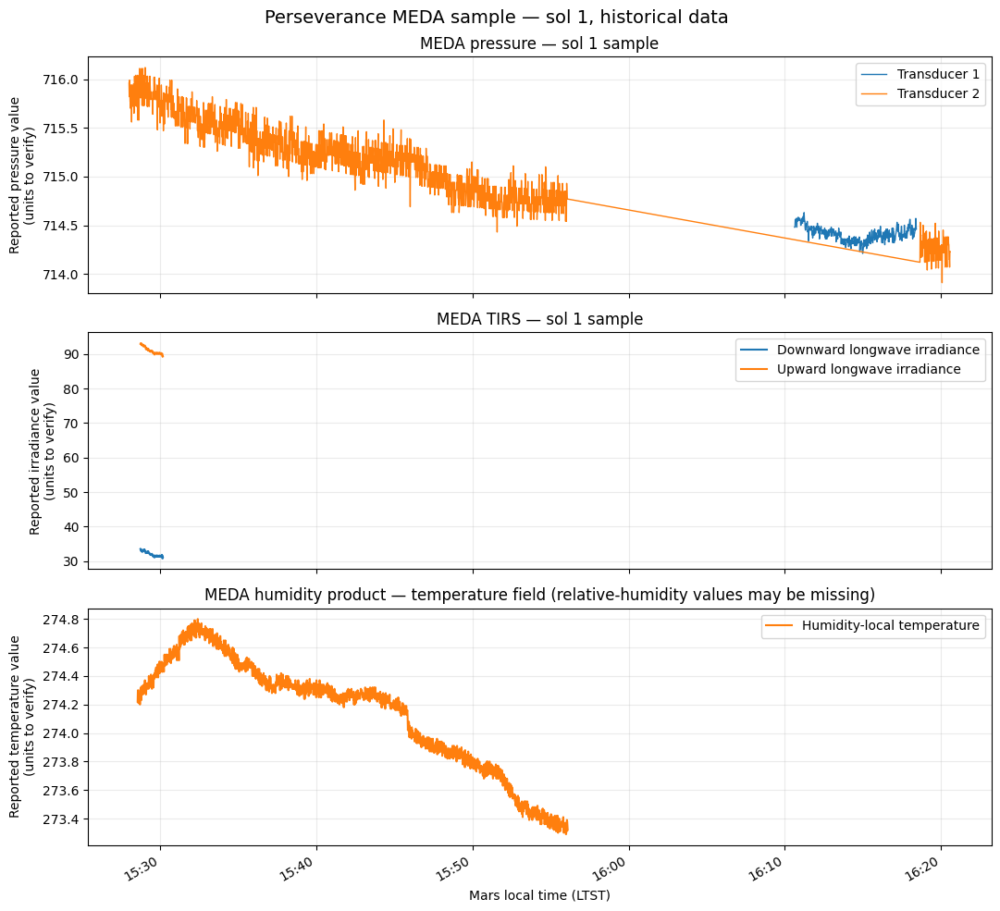


Saved plot: /content/drive/MyDrive/Marswalk/Outputs/MEDA_sol1_sample.png


In [28]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd

raw_dir = Path("/content/drive/MyDrive/Marswalk/Raw data")
output_dir = Path("/content/drive/MyDrive/Marswalk/Outputs")
output_dir.mkdir(parents=True, exist_ok=True)

files = {
    "Pressure": raw_dir / "WE__0001___________DER_PS__________________P02.csv",
    "TIRS": raw_dir / "WE__0001___________DER_TIRS________________P04.csv",
    "Humidity": raw_dir / "WE__0001___________DER_RHS_________________P03.csv",
}

for name, path in files.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name} CSV not found: {path}")

def add_local_time_minutes(df):
    """Extract Mars local-time minutes from strings like '0001 15:28:01'."""
    if "LTST" not in df.columns:
        raise ValueError("Expected an LTST column.")

    def to_minutes(value):
        match = re.search(r"(\d{2}):(\d{2}):(\d{2})", str(value))
        if not match:
            return float("nan")
        hour, minute, second = map(int, match.groups())
        return hour * 60 + minute + second / 60

    result = df.copy()
    result["LOCAL_TIME_MIN"] = result["LTST"].map(to_minutes)
    return result.sort_values("LOCAL_TIME_MIN")

ps = add_local_time_minutes(pd.read_csv(files["Pressure"]))
tirs = add_local_time_minutes(pd.read_csv(files["TIRS"]))
rhs = add_local_time_minutes(pd.read_csv(files["Humidity"]))

print("Coverage:")
for name, df in [("Pressure", ps), ("TIRS", tirs), ("Humidity", rhs)]:
    print(
        f"{name}: {len(df):,} rows; "
        f"LTST {df['LTST'].iloc[0]} to {df['LTST'].iloc[-1]}"
    )

rh_valid = rhs["LOCAL_RELATIVE_HUMIDITY"].notna().sum()
print(
    f"\nRelative-humidity values present: {rh_valid:,} / {len(rhs):,}"
)
print("Humidity product columns:", list(rhs.columns))

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

# Pressure, separated by the reported transducer identifier.
for transducer, group in ps.groupby("TRANSDUCER", dropna=False):
    axes[0].plot(
        group["LOCAL_TIME_MIN"],
        group["PRESSURE"],
        linewidth=1,
        label=f"Transducer {transducer}",
    )
axes[0].set_title("MEDA pressure — sol 1 sample")
axes[0].set_ylabel("Reported pressure value\n(units to verify)")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    tirs["LOCAL_TIME_MIN"],
    tirs["DOWNWARD_LW_IRRADIANCE"],
    label="Downward longwave irradiance",
)
axes[1].plot(
    tirs["LOCAL_TIME_MIN"],
    tirs["UPWARD_LW_IRRADIANCE"],
    label="Upward longwave irradiance",
)
axes[1].set_title("MEDA TIRS — sol 1 sample")
axes[1].set_ylabel("Reported irradiance value\n(units to verify)")
axes[1].legend()
axes[1].grid(alpha=0.25)

axes[2].plot(
    rhs["LOCAL_TIME_MIN"],
    rhs["HUMIDITY_LOCAL_TEMP"],
    color="tab:orange",
    label="Humidity-local temperature",
)
axes[2].set_title(
    "MEDA humidity product — temperature field "
    "(relative-humidity values may be missing)"
)
axes[2].set_ylabel("Reported temperature value\n(units to verify)")
axes[2].set_xlabel("Mars local time (LTST)")
axes[2].legend()
axes[2].grid(alpha=0.25)

# Label x-axis in HH:MM using the sol-local-time minute values.
tick_positions = sorted(
    set(
        int(round(value / 10) * 10)
        for value in pd.concat(
            [ps["LOCAL_TIME_MIN"], tirs["LOCAL_TIME_MIN"], rhs["LOCAL_TIME_MIN"]]
        ).dropna()
    )
)
axes[2].set_xticks(tick_positions)
axes[2].set_xticklabels(
    [f"{minute // 60:02d}:{minute % 60:02d}" for minute in tick_positions],
    rotation=30,
    ha="right",
)

fig.suptitle(
    "Perseverance MEDA sample — sol 1, historical data",
    fontsize=14,
)
fig.tight_layout()

plot_path = output_dir / "MEDA_sol1_sample.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"\nSaved plot: {plot_path}")

In [29]:
from pathlib import Path
import pandas as pd

raw_dir = Path("/content/drive/MyDrive/Marswalk/Raw data")
output_dir = Path("/content/drive/MyDrive/Marswalk/Outputs")
output_dir.mkdir(parents=True, exist_ok=True)

files = {
    "PS": raw_dir / "WE__0001___________DER_PS__________________P02.csv",
    "TIRS": raw_dir / "WE__0001___________DER_TIRS________________P04.csv",
    "RHS": raw_dir / "WE__0001___________DER_RHS_________________P03.csv",
}

for product, path in files.items():
    if not path.is_file():
        raise FileNotFoundError(f"{product} file not found: {path}")

def load_product(product, path):
    df = pd.read_csv(path)

    if "SCLK" not in df.columns:
        raise ValueError(f"{path.name} has no SCLK column.")

    # Keep one row per clock tick if duplicates exist; report them for review.
    duplicate_count = int(df["SCLK"].duplicated().sum())
    if duplicate_count:
        print(f"Warning: {product} has {duplicate_count} duplicate SCLK rows; keeping the first.")
        df = df.drop_duplicates("SCLK", keep="first")

    # Keep each product's local times so we can detect any clock/time mismatches.
    rename = {}
    if "LTST" in df.columns:
        rename["LTST"] = f"LTST_{product}"
    if "LMST" in df.columns:
        rename["LMST"] = f"LMST_{product}"

    df = df.rename(columns=rename)
    return df

ps = load_product("PS", files["PS"])
tirs = load_product("TIRS", files["TIRS"])
rhs = load_product("RHS", files["RHS"])

# Outer joins retain all samples, including times when only one instrument has data.
merged = ps.merge(tirs, on="SCLK", how="outer", validate="one_to_one")
merged = merged.merge(rhs, on="SCLK", how="outer", validate="one_to_one")
merged = merged.sort_values("SCLK").reset_index(drop=True)

# Convenient display time: use whichever product has a timestamp at that SCLK.
ltst_cols = [c for c in ("LTST_PS", "LTST_TIRS", "LTST_RHS") if c in merged.columns]
if ltst_cols:
    merged["LTST"] = merged[ltst_cols].bfill(axis=1).iloc[:, 0]

# Check whether products report differing local-time strings for shared SCLK values.
if len(ltst_cols) > 1:
    merged["LTST_MISMATCH"] = merged[ltst_cols].nunique(axis=1, dropna=True) > 1
    mismatch_count = int(merged["LTST_MISMATCH"].sum())
else:
    mismatch_count = 0

output_path = output_dir / "MEDA_sol1_merged_by_SCLK.csv"
merged.to_csv(output_path, index=False)

print(f"Saved merged table: {output_path}")
print(f"Rows after outer join: {len(merged):,}")
print(f"SCLK range: {merged['SCLK'].min()} to {merged['SCLK'].max()}")
print(f"Rows with differing LTST strings across products: {mismatch_count}")

print("\nPer-product availability in merged table:")
for product, columns in {
    "PS": ["PRESSURE"],
    "TIRS": ["DOWNWARD_LW_IRRADIANCE", "UPWARD_LW_IRRADIANCE"],
    "RHS": ["HUMIDITY_LOCAL_TEMP", "LOCAL_RELATIVE_HUMIDITY"],
}.items():
    present_columns = [c for c in columns if c in merged.columns]
    if present_columns:
        print(f"{product}:")
        for column in present_columns:
            print(f"  {column}: {merged[column].notna().sum():,} valid rows")

print("\nPreview:")
display(merged.head(10))

Saved merged table: /content/drive/MyDrive/Marswalk/Outputs/MEDA_sol1_merged_by_SCLK.csv
Rows after outer join: 2,332
SCLK range: 667042464 to 667045704
Rows with differing LTST strings across products: 0

Per-product availability in merged table:
PS:
  PRESSURE: 2,330 valid rows
TIRS:
  DOWNWARD_LW_IRRADIANCE: 90 valid rows
  UPWARD_LW_IRRADIANCE: 90 valid rows
RHS:
  HUMIDITY_LOCAL_TEMP: 1,698 valid rows
  LOCAL_RELATIVE_HUMIDITY: 0 valid rows

Preview:


,SCLK,LMST_PS,LTST_PS,PRESSURE,PRESSURE_UNCERTAINTY,TRANSDUCER,LMST_TIRS,LTST_TIRS,DOWNWARD_LW_IRRADIANCE,DOWNWARD_LW_IRRADIANCE_UNCERTAINTY,...,LMST_RHS,LTST_RHS,LOCAL_RELATIVE_HUMIDITY,LOCAL_RELATIVE_HUMIDITY_UNCERTAINTY,HUMIDITY_LOCAL_TEMP,HUMIDITY_LOCAL_TEMP_UNCERTAINTY,VOLUME_MIXING_RATIO,VOLUME_MIXING_RATIO_UNCERTAINTY,LTST,LTST_MISMATCH
0,667042464,00001M16:05:31.315,0001 15:28:01,715.96,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:01,False
1,667042465,00001M16:05:32.289,0001 15:28:02,715.82,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:02,False
2,667042466,00001M16:05:33.262,0001 15:28:03,715.99,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:03,False
3,667042467,00001M16:05:34.235,0001 15:28:04,715.92,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:04,False
4,667042468,00001M16:05:35.208,0001 15:28:05,715.77,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:05,False
5,667042469,00001M16:05:36.182,0001 15:28:06,715.78,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:06,False
6,667042470,00001M16:05:37.155,0001 15:28:07,715.70,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:07,False
7,667042471,00001M16:05:38.128,0001 15:28:08,715.94,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:08,False
8,667042472,00001M16:05:39.101,0001 15:28:09,715.86,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:09,False
9,667042473,00001M16:05:40.075,0001 15:28:10,715.79,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0001 15:28:10,False


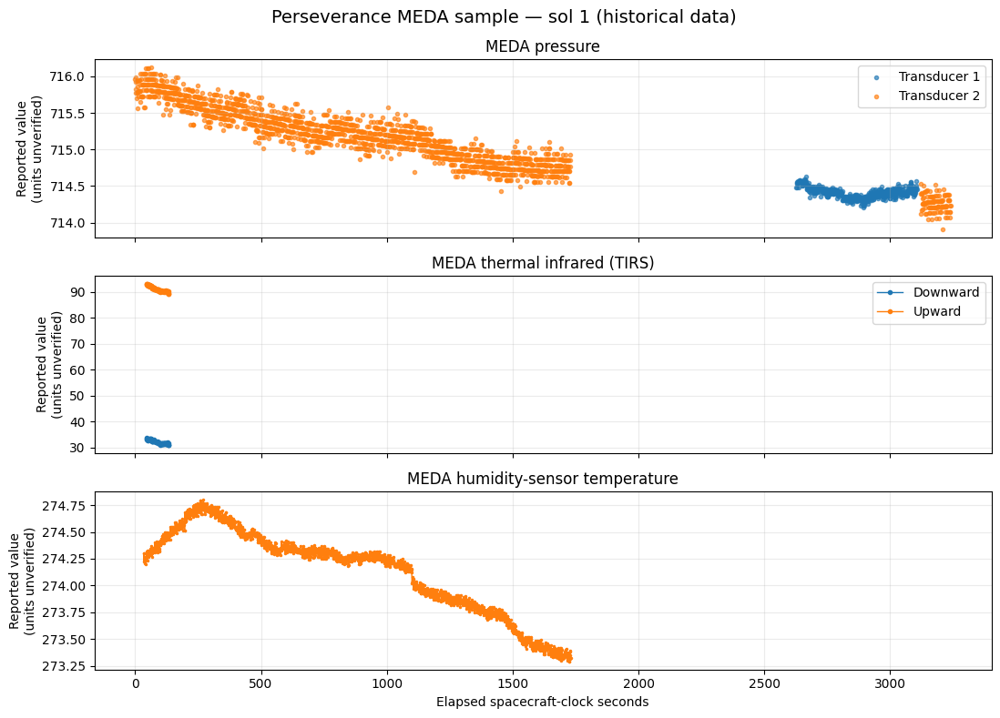

Saved figure: /content/drive/MyDrive/Marswalk/Outputs/MEDA_sol1_presentation.png
Saved summary: /content/drive/MyDrive/Marswalk/Outputs/MEDA_sol1_summary.txt
MEDA sample summary
Sol: 1 (from the LTST strings in the supplied files)
SCLK range: 667042464 to 667045704
Pressure valid rows: 2330
TIRS downward valid rows: 90
TIRS upward valid rows: 90
Humidity-sensor temperature valid rows: 1698
Relative-humidity valid rows: 0

Important: verify measurement units and quality flags from the PDS product labels
before interpreting values. This sol-1 sample is not contemporaneous with the
sol-836 example image and is not a forecast or safety assessment.



In [30]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

output_dir = Path("/content/drive/MyDrive/Marswalk/Outputs")
input_path = output_dir / "MEDA_sol1_merged_by_SCLK.csv"

if not input_path.exists():
    raise FileNotFoundError(f"Merged MEDA file not found: {input_path}")

df = pd.read_csv(input_path).sort_values("SCLK")
df["ELAPSED_SECONDS"] = df["SCLK"] - df["SCLK"].min()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

# Pressure: plot separate points per transducer; do not connect across gaps.
for sensor, group in df.dropna(subset=["PRESSURE"]).groupby("TRANSDUCER"):
    axes[0].scatter(
        group["ELAPSED_SECONDS"], group["PRESSURE"],
        s=9, alpha=0.65, label=f"Transducer {sensor:g}"
    )
axes[0].set_title("MEDA pressure")
axes[0].set_ylabel("Reported value\n(units unverified)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Plot available TIRS samples only.
for column, label in [
    ("DOWNWARD_LW_IRRADIANCE", "Downward"),
    ("UPWARD_LW_IRRADIANCE", "Upward"),
]:
    valid = df.dropna(subset=[column])
    axes[1].plot(
        valid["ELAPSED_SECONDS"], valid[column],
        marker="o", markersize=3, linewidth=1, label=label
    )
axes[1].set_title("MEDA thermal infrared (TIRS)")
axes[1].set_ylabel("Reported value\n(units unverified)")
axes[1].legend()
axes[1].grid(alpha=0.25)

# Relative humidity is missing in this file; show the available sensor temperature.
valid_temp = df.dropna(subset=["HUMIDITY_LOCAL_TEMP"])
axes[2].plot(
    valid_temp["ELAPSED_SECONDS"], valid_temp["HUMIDITY_LOCAL_TEMP"],
    marker=".", markersize=3, linewidth=1, color="tab:orange"
)
axes[2].set_title("MEDA humidity-sensor temperature")
axes[2].set_ylabel("Reported value\n(units unverified)")
axes[2].set_xlabel("Elapsed spacecraft-clock seconds")
axes[2].grid(alpha=0.25)

fig.suptitle("Perseverance MEDA sample — sol 1 (historical data)", fontsize=14)
fig.tight_layout()

png_path = output_dir / "MEDA_sol1_presentation.png"
fig.savefig(png_path, dpi=180, bbox_inches="tight")
plt.show()

summary = f"""MEDA sample summary
Sol: 1 (from the LTST strings in the supplied files)
SCLK range: {df['SCLK'].min()} to {df['SCLK'].max()}
Pressure valid rows: {df['PRESSURE'].notna().sum()}
TIRS downward valid rows: {df['DOWNWARD_LW_IRRADIANCE'].notna().sum()}
TIRS upward valid rows: {df['UPWARD_LW_IRRADIANCE'].notna().sum()}
Humidity-sensor temperature valid rows: {df['HUMIDITY_LOCAL_TEMP'].notna().sum()}
Relative-humidity valid rows: {df['LOCAL_RELATIVE_HUMIDITY'].notna().sum()}

Important: verify measurement units and quality flags from the PDS product labels
before interpreting values. This sol-1 sample is not contemporaneous with the
sol-836 example image and is not a forecast or safety assessment.
"""
summary_path = output_dir / "MEDA_sol1_summary.txt"
summary_path.write_text(summary)

print(f"Saved figure: {png_path}")
print(f"Saved summary: {summary_path}")
print(summary)

In [31]:
from pathlib import Path
import subprocess
import sys
import requests

pdf_url = (
    "https://pds-atmospheres.nmsu.edu/PDS/data/PDS4/Mars2020/"
    "mars2020_meda/document/meda_env_rdr_sis.pdf"
)
pdf_path = Path("/content/drive/MyDrive/Marswalk/Outputs/meda_env_rdr_sis.pdf")

# Install the PDF text-extraction library if needed.
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pymupdf"])
import fitz

pdf_path.parent.mkdir(parents=True, exist_ok=True)

if not pdf_path.exists():
    response = requests.get(pdf_url, timeout=60)
    response.raise_for_status()
    pdf_path.write_bytes(response.content)

doc = fitz.open(pdf_path)
print(f"Opened {pdf_path.name}: {len(doc)} pages")

terms = [
    "PRESSURE",
    "DOWNWARD_LW_IRRADIANCE",
    "UPWARD_LW_IRRADIANCE",
    "HUMIDITY_LOCAL_TEMP",
    "LOCAL_RELATIVE_HUMIDITY",
    "VOLUME_MIXING_RATIO",
    "UNCERTAINTY",
    "TRANSDUCER",
]

matches = []
for page_number, page in enumerate(doc, start=1):
    text = page.get_text("text")
    upper_text = text.upper()
    found = [term for term in terms if term in upper_text]
    if found:
        matches.append((page_number, found, text))

if not matches:
    print(
        "No exact column names found in the extracted PDF text. "
        "Try searching the PDF manually for 'pressure', 'irradiance', "
        "'humidity', or 'CSV'."
    )
else:
    for page_number, found, text in matches:
        print(f"\n--- PDF page {page_number}; matched: {', '.join(found)} ---")
        print(text[:7000])

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Opened meda_env_rdr_sis.pdf: 51 pages

--- PDF page 6; matched: PRESSURE ---
 
    Pag. 6 
Ed./Iss. : Issue 04 
Doc.: CAB-MEDA-SPC-0007 
 
 
 
6
 
NAIF Navigation and Ancillary Information Facility 
 
NASA National Aeronautics and Space Administration 
 
ODL 
Object Description Language 
 
ODS 
Operations Data Store 
 
OPGS Operations Products Generation Sub-system 
 
OT 
Observation Table 
 
PCB 
Printed Circuit Board 
 
PDS 
Planetary Data System 
 
PRT 
Platinum Resistance Thermometer 
 
PS 
Pressure Sensor 
 
PSU 
Power Supply Unit 
 
RDR 
Reduced Data Record 
 
RDS 
Radiation and Dust Sensor 
 
RFB 
Rover Front Body 
 
RSM Remote Sensing Mast  
 
RTD 
Resistance Temperature Detector 
 
MEDA Mars Environmental Dynamics Analyzer 
 
RAMP Rover Avionics Mounting Panel 
 
SDF 
Science Data Frame 
 
SDP 
Science Data Product 
 
SEF 
Single Event Failure 
 
SIS 
Software Interface Specification 
 
SOL 
It represents 1 (one) solar day (from midnight to midnight) 
 
SUSW Start-up Software 

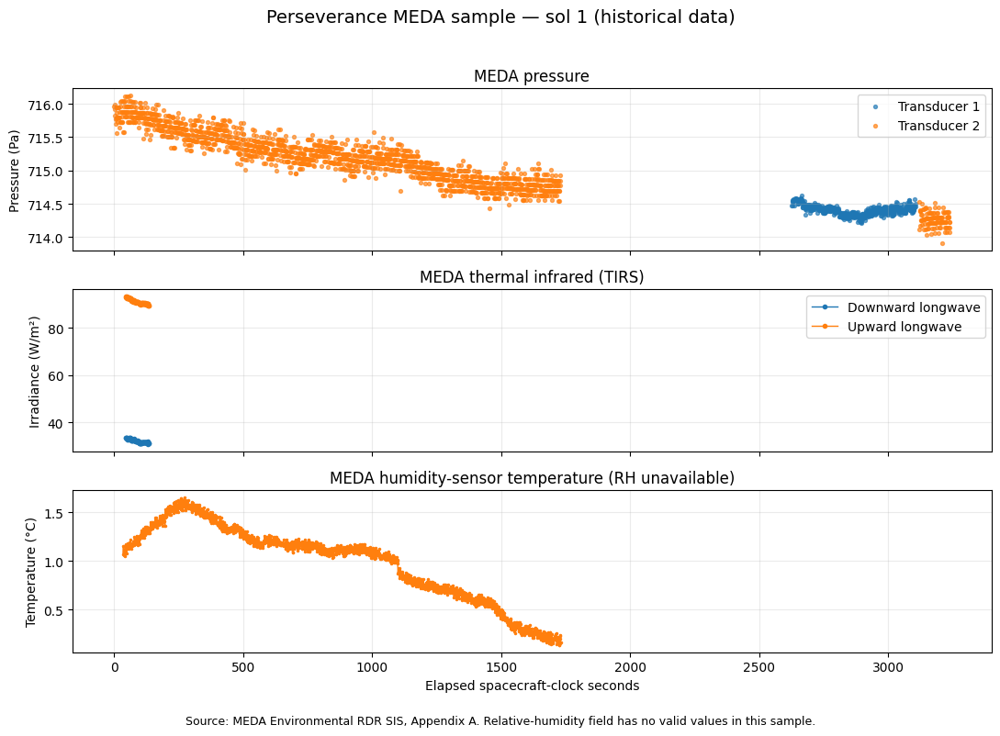

Saved verified-unit figure: /content/drive/MyDrive/Marswalk/Outputs/MEDA_sol1_presentation_verified_units.png
Verified from the MEDA Environmental RDR SIS:
- PRESSURE: Pa
- DOWNWARD_LW_IRRADIANCE / UPWARD_LW_IRRADIANCE: W/m²
- HUMIDITY_LOCAL_TEMP: K in the source; plotted here as °C
- LOCAL_RELATIVE_HUMIDITY valid rows: 0


In [32]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

output_dir = Path("/content/drive/MyDrive/Marswalk/Outputs")
input_path = output_dir / "MEDA_sol1_merged_by_SCLK.csv"

df = pd.read_csv(input_path).sort_values("SCLK")
df["ELAPSED_SECONDS"] = df["SCLK"] - df["SCLK"].min()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

# Pressure in pascals; show each transducer separately.
for sensor, group in df.dropna(subset=["PRESSURE"]).groupby("TRANSDUCER"):
    axes[0].scatter(
        group["ELAPSED_SECONDS"], group["PRESSURE"],
        s=8, alpha=0.65, label=f"Transducer {sensor:g}"
    )
axes[0].set_title("MEDA pressure")
axes[0].set_ylabel("Pressure (Pa)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Calibrated longwave irradiance in W/m².
for column, label in [
    ("DOWNWARD_LW_IRRADIANCE", "Downward longwave"),
    ("UPWARD_LW_IRRADIANCE", "Upward longwave"),
]:
    valid = df.dropna(subset=[column])
    axes[1].plot(
        valid["ELAPSED_SECONDS"], valid[column],
        marker="o", markersize=3, linewidth=1, label=label
    )
axes[1].set_title("MEDA thermal infrared (TIRS)")
axes[1].set_ylabel("Irradiance (W/m²)")
axes[1].legend()
axes[1].grid(alpha=0.25)

# Plot available humidity-sensor temperature; convert K to °C for readability.
valid_temp = df.dropna(subset=["HUMIDITY_LOCAL_TEMP"]).copy()
valid_temp["TEMP_C"] = valid_temp["HUMIDITY_LOCAL_TEMP"] - 273.15
axes[2].plot(
    valid_temp["ELAPSED_SECONDS"], valid_temp["TEMP_C"],
    marker=".", markersize=3, linewidth=1, color="tab:orange"
)
axes[2].set_title("MEDA humidity-sensor temperature (RH unavailable)")
axes[2].set_ylabel("Temperature (°C)")
axes[2].set_xlabel("Elapsed spacecraft-clock seconds")
axes[2].grid(alpha=0.25)

fig.suptitle("Perseverance MEDA sample — sol 1 (historical data)", fontsize=14)
fig.text(
    0.5, 0.005,
    "Source: MEDA Environmental RDR SIS, Appendix A. "
    "Relative-humidity field has no valid values in this sample.",
    ha="center", fontsize=9
)
fig.tight_layout(rect=(0, 0.03, 1, 0.96))

png_path = output_dir / "MEDA_sol1_presentation_verified_units.png"
fig.savefig(png_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved verified-unit figure: {png_path}")
print("Verified from the MEDA Environmental RDR SIS:")
print("- PRESSURE: Pa")
print("- DOWNWARD_LW_IRRADIANCE / UPWARD_LW_IRRADIANCE: W/m²")
print("- HUMIDITY_LOCAL_TEMP: K in the source; plotted here as °C")
print(f"- LOCAL_RELATIVE_HUMIDITY valid rows: {df['LOCAL_RELATIVE_HUMIDITY'].notna().sum()}")

Layer controls on map: 1
Saved map with MEDA: /content/drive/MyDrive/Marswalk/Outputs/marswalk_eva_map_with_meda.html (4,945,196 bytes)



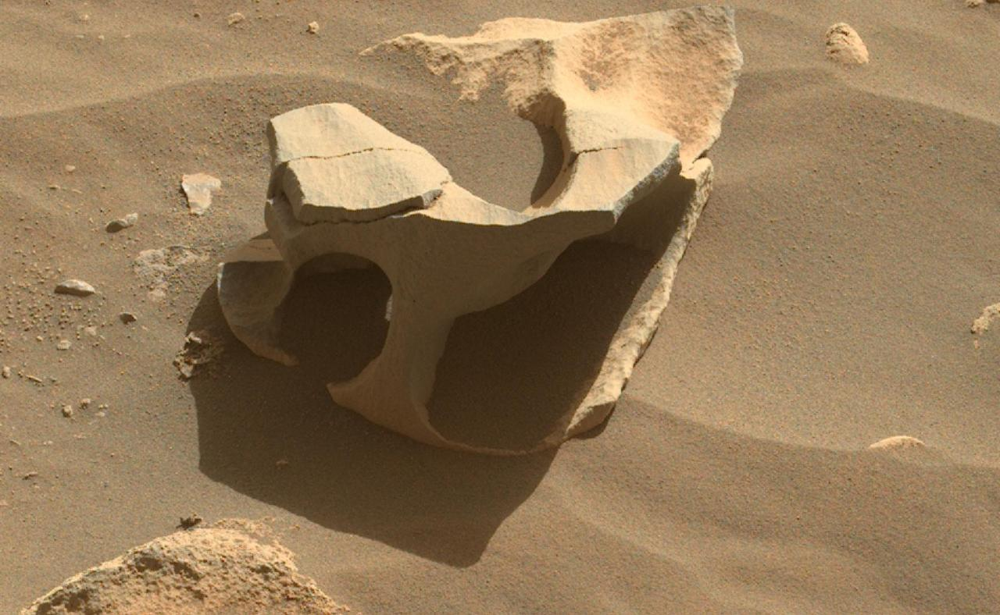
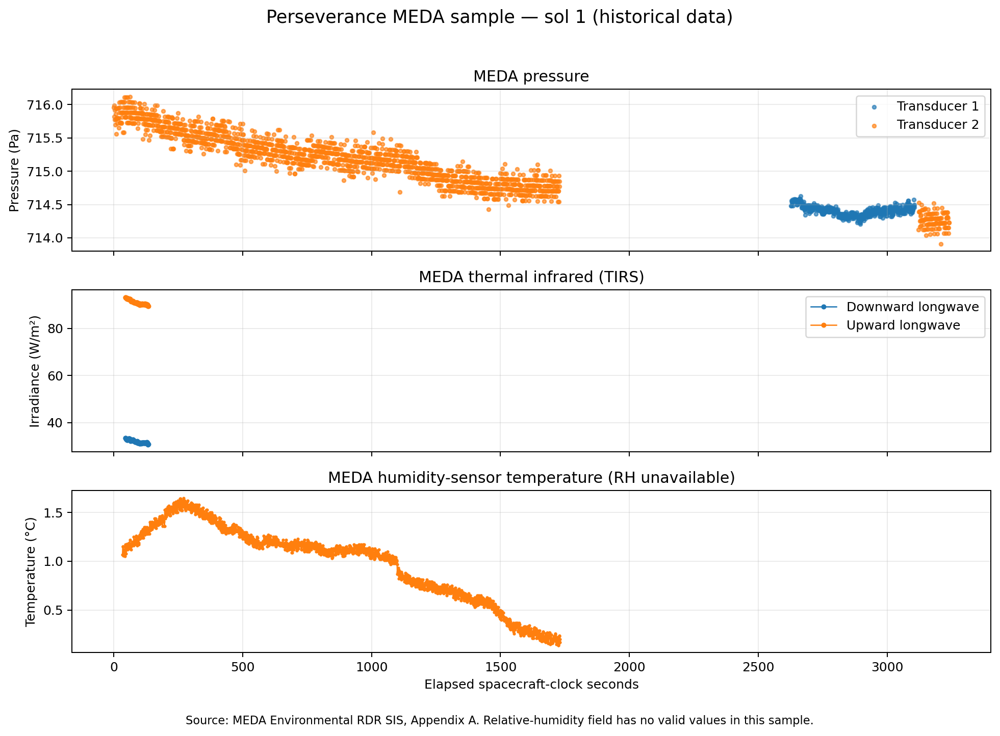
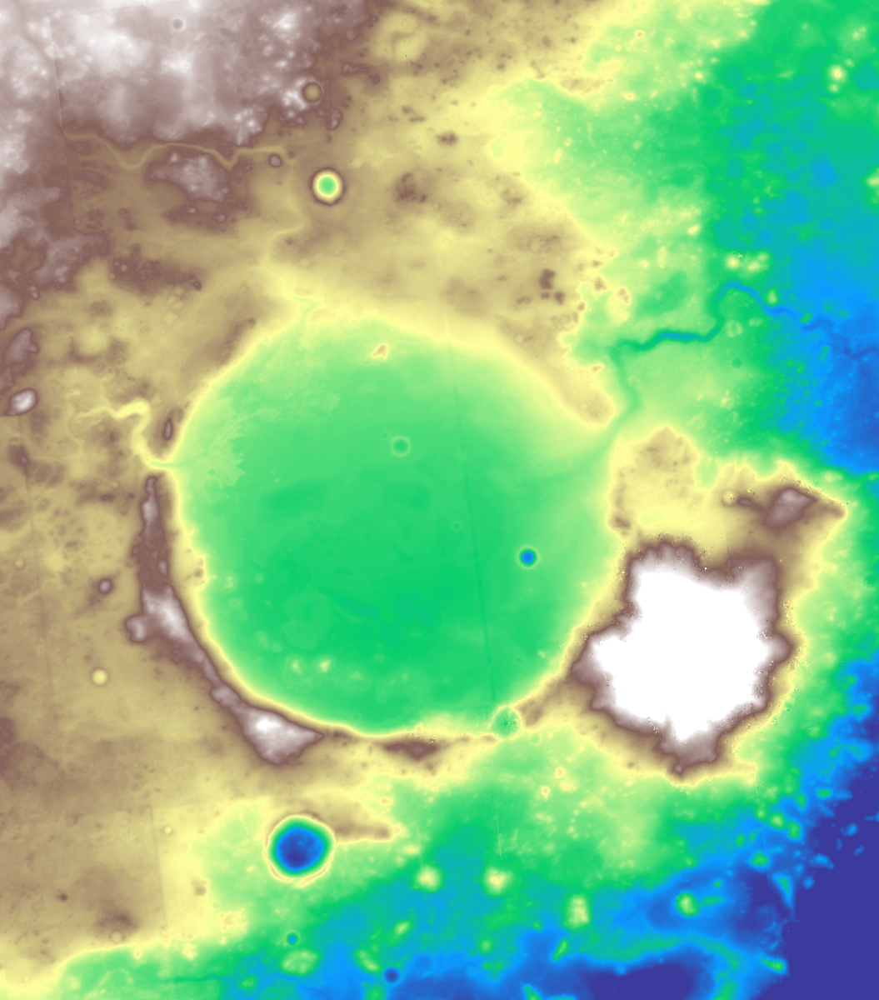
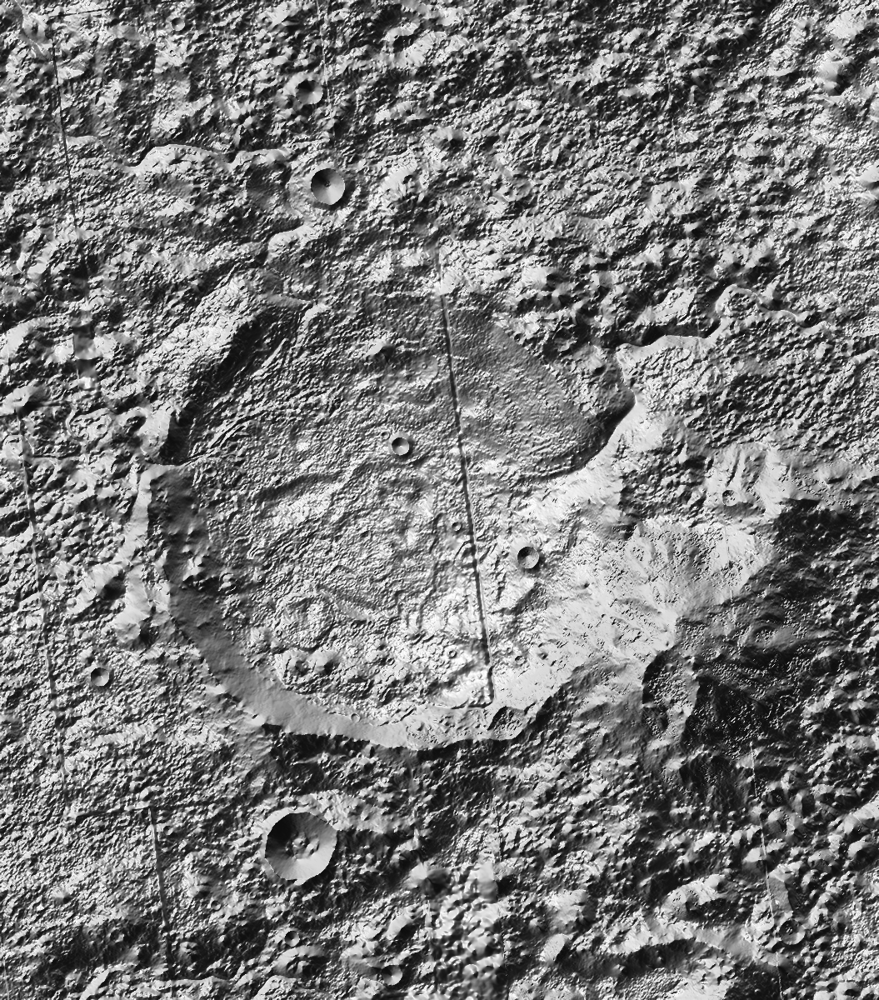
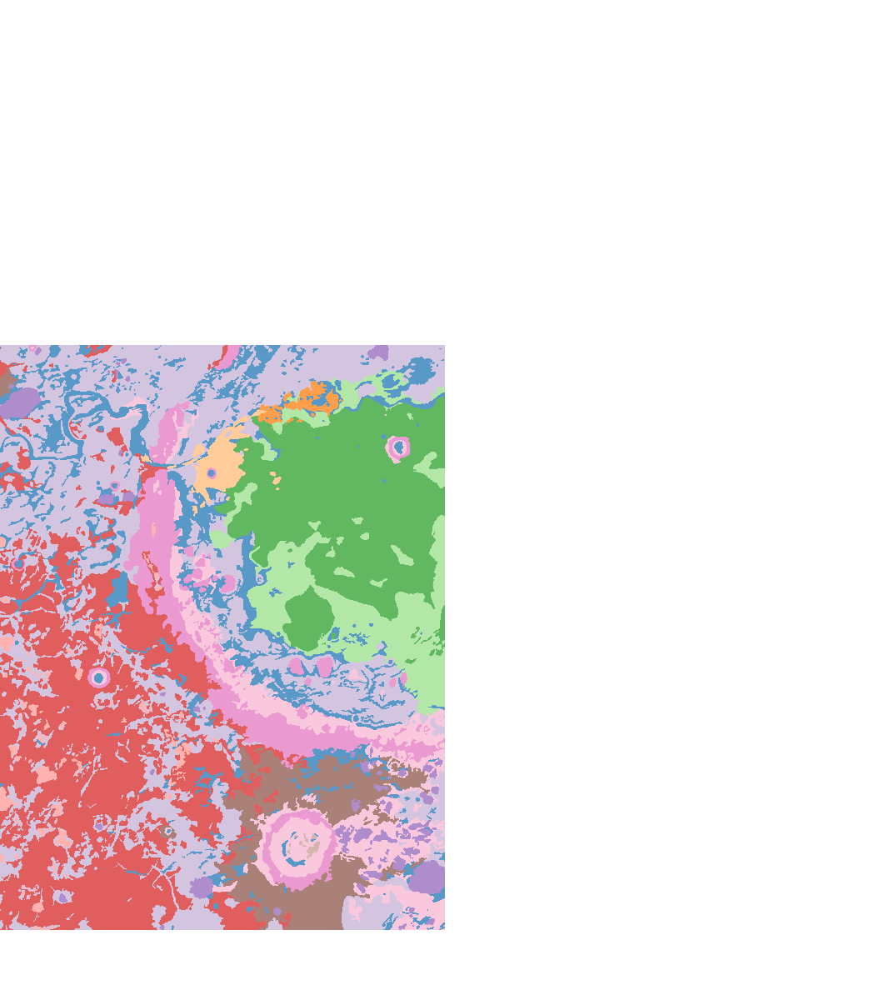
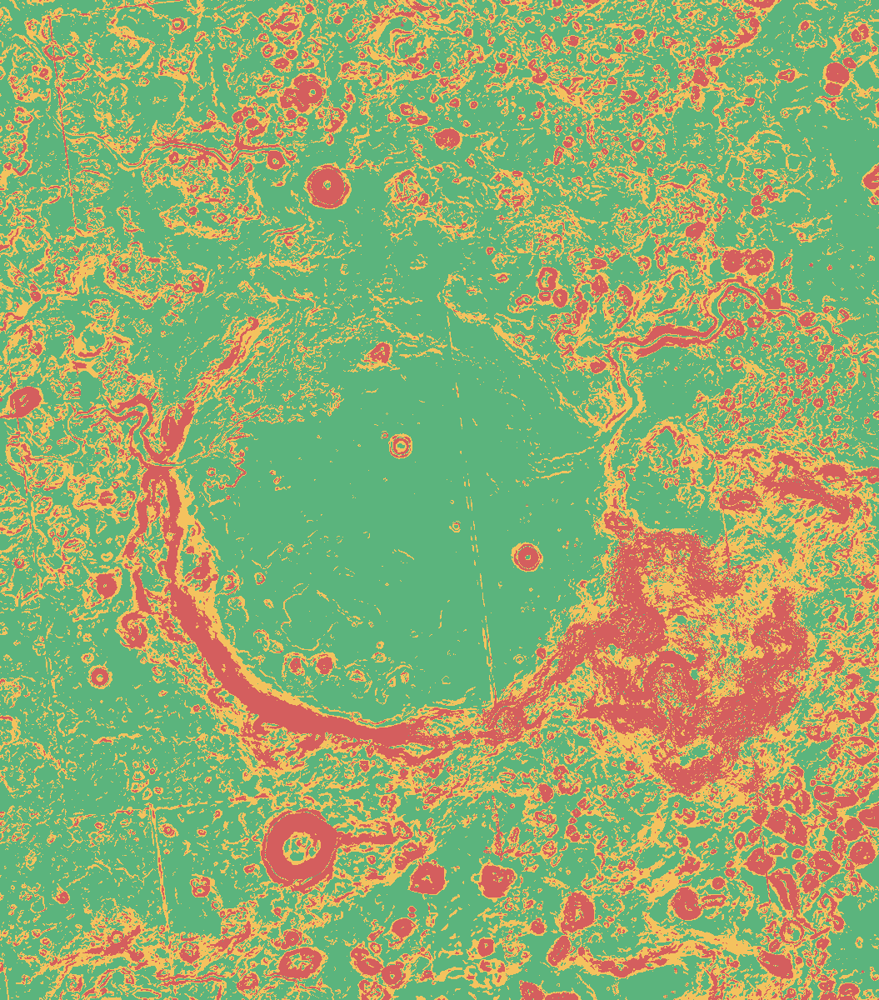

In [33]:
from pathlib import Path
import base64
import folium
from folium import Element
from IPython.display import display

# Use the existing full EVA map; don't create another map.
if "m" not in globals() or not isinstance(m, folium.Map):
    raise RuntimeError(
        "The working Folium map named 'm' isn't in memory. "
        "Run the original EVA map-building cells first."
    )

output_dir = Path("/content/drive/MyDrive/Marswalk/Outputs")
meda_png = output_dir / "MEDA_sol1_presentation_verified_units.png"

if not meda_png.is_file():
    raise FileNotFoundError(f"MEDA plot not found: {meda_png}")

# Make this cell safe to rerun: remove its previous panel and old controls.
for key, child in list(m.get_root().html._children.items()):
    try:
        rendered = child.render()
    except Exception:
        rendered = ""
    if 'id="marswalk-meda-panel"' in rendered:
        del m.get_root().html._children[key]

for key, child in list(m._children.items()):
    if isinstance(child, folium.LayerControl):
        del m._children[key]

# Embed the MEDA chart in a small panel. Clicks outside the panel still reach the map.
meda_data = base64.b64encode(meda_png.read_bytes()).decode("ascii")
m.get_root().html.add_child(Element(f"""
<div style="position:fixed; top:12px; left:12px; z-index:9998;
            pointer-events:none;">
  <div id="marswalk-meda-panel"
       style="width:min(330px,32vw); max-height:34vh; overflow:auto;
              pointer-events:auto; background:white;
              border:1px solid #536273; border-radius:8px;
              padding:8px; box-shadow:0 2px 8px #0005;
              font:12px/1.35 Arial,sans-serif;">
    <b>Perseverance MEDA · Sol 1 historical sample</b>
    <img src="data:image/png;base64,{meda_data}"
         alt="MEDA sol 1 pressure, TIRS irradiance, and humidity-sensor temperature plots"
         style="display:block; width:100%; height:auto; margin:5px 0;">
    <div>Relative humidity is unavailable in this sample. These historical
         measurements are not contemporaneous with the sol-836 image and
         are not a forecast.</div>
  </div>
</div>
"""))

# Add exactly one layer control after the map layers are already present.
folium.LayerControl(position="topright", collapsed=False).add_to(m)

control_count = sum(isinstance(c, folium.LayerControl) for c in m._children.values())
assert control_count == 1, f"Expected one layer control; found {control_count}"

final_html = output_dir / "marswalk_eva_map_with_meda.html"
m.save(str(final_html))

print(f"Layer controls on map: {control_count}")
print(f"Saved map with MEDA: {final_html} ({final_html.stat().st_size:,} bytes)")
display(m)